# PulokFrac-Q++ — Manuscript-Locked Reproducibility Notebook
### Medical Image Analysis submission-preparation edition

This notebook makes the **experimental record the single source of truth** for the manuscript.

It reproduces the supplied manuscript protocol: full BFMRX development set, pre-training duplicate audit, duplicate-grouped five-fold CV, one shared fold registry for all eight models, inner group-aware validation, the realized fold-1/folds-2–5 epoch schedule, the three classical baselines, the two Mamba-family models under the documented substitute-kernel condition, NCGNN, PulokFrac-Q and PulokFrac-Q++.

**Safety rule:** old manuscript values are stored only as a comparison registry. They are never used to calculate metrics, figures, thresholds, p-values or conclusions.

## Critical mismatches corrected from the supplied working notebook

The supplied working notebook had protocol drift relative to the manuscript: a 3,800-image development cap, a 10-epoch configuration, removed classical baselines, a 192-d PulokFrac-Q++ global projection, and a locked-test stage that omitted EfficientNetV2-B2. This version removes those inconsistencies.

Run Sections 1–6 first. If any preflight check fails, **do not train** and do not copy any old manuscript number.

In [1]:
# 1. Dependencies
import sys, subprocess, shutil
PKGS = ["timm>=1.0.15","ImageHash>=4.3.1","umap-learn>=0.5.7","statsmodels>=0.14"]
try:
    if shutil.which("uv"):
        cmd=["uv","pip","install","--system","--break-system-packages","-q",*PKGS]
    else:
        cmd=[sys.executable,"-m","pip","install","-q","--break-system-packages",*PKGS]
    res=subprocess.run(cmd,capture_output=True,text=True)
    print("Dependency setup:", "OK" if res.returncode==0 else (res.stderr or res.stdout)[-1200:])
except Exception as e:
    print("Dependency setup notice:",e)

Dependency setup: OK


In [2]:
# 2. Imports, protocol lock, runtime switches
import os, gc, json, math, time, random, hashlib, warnings, platform, sys
from pathlib import Path
from collections import defaultdict
from contextlib import contextmanager
from copy import deepcopy

warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM","false")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile, ImageFilter, ImageEnhance
ImageFile.LOAD_TRUNCATED_IMAGES=True

import cv2, imagehash
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF
import timm

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,
    average_precision_score,confusion_matrix,matthews_corrcoef,
    cohen_kappa_score,balanced_accuracy_score,brier_score_loss,
    roc_curve,precision_recall_curve
)
from sklearn.calibration import calibration_curve
from scipy.stats import wilcoxon, binomtest
from statsmodels.stats.multitest import multipletests

try:
    import umap
    UMAP_AVAILABLE=True
except Exception:
    UMAP_AVAILABLE=False

SEED=42
IMAGE_SIZE=224
NUM_FOLDS=5
INNER_FOLDS=5
EPOCH_BUDGET_BY_FOLD={1:6,2:5,3:5,4:5,5:5}
EARLY_STOP_PATIENCE=2
MIN_EPOCHS_BEFORE_STOP=3
BASE_LR=1e-4
WEIGHT_DECAY=1e-4
BATCH_SIZE=48
SEG_BATCH_SIZE=16
GRADCAM_BATCH_SIZE=32
NUM_WORKERS=0 if os.name=="nt" else min(4,os.cpu_count() or 2)
PREFETCH_FACTOR=2

N_QUBITS=4
N_Q_LAYERS=3
UNCERTAINTY_TAU=0.55
UNCERTAINTY_SHARPNESS=8.0
PSEUDO_MASK_PERCENTILE=78
MASK_LOSS_WEIGHT=0.45
ROI_PROVIDER="Swin-UMamba"

MODEL_ORDER=[
    "ResNet50","Swin-T","EfficientNetV2-B2",
    "Mamba-UNet","Swin-UMamba","NCGNN",
    "PulokFrac-Q","PulokFrac-Q++"
]
REFERENCE_MODEL="PulokFrac-Q++"
LOCKED_TEST_MODELS=["EfficientNetV2-B2","PulokFrac-Q","PulokFrac-Q++"]

# Reproduces the implementation condition stated in the manuscript.
FORCE_PYTORCH_MAMBA_FALLBACK=True

RUN_MAIN_CV=True
RUN_LOCKED_TEST=True
RUN_ABLATION=True
RUN_QUANTUM_SENSITIVITY=True
RUN_CALIBRATION=True
RUN_PRIMARY_FIGURES=True
RUN_XAI_GALLERY=True
RUN_GROUP_ROBUSTNESS=True
RUN_SUPPLEMENTARY_VISUALS=False
STRICT_MANUSCRIPT_GUARD=True

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True

DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP=torch.cuda.is_available()

WORKSPACE=Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
OUTPUT_ROOT=WORKSPACE/"pulokfrac_media"
FIG_DIR=OUTPUT_ROOT/"figures"; TABLE_DIR=OUTPUT_ROOT/"tables"
CKPT_DIR=OUTPUT_ROOT/"checkpoints"; PRED_DIR=OUTPUT_ROOT/"predictions"
MASK_DIR=OUTPUT_ROOT/"masks"; META_DIR=OUTPUT_ROOT/"metadata"
SUPP_DIR=OUTPUT_ROOT/"supplementary_visuals"
for p in [OUTPUT_ROOT,FIG_DIR,TABLE_DIR,CKPT_DIR,PRED_DIR,MASK_DIR,META_DIR,SUPP_DIR]:
    p.mkdir(parents=True,exist_ok=True)

OKABE_ITO=["#000000","#E69F00","#56B4E9","#009E73","#F0E442","#0072B2","#D55E00","#CC79A7"]
MODEL_COLORS=dict(zip(MODEL_ORDER,OKABE_ITO))
plt.rcParams.update({"figure.dpi":110,"savefig.dpi":600,"font.size":12,"figure.facecolor":"white","savefig.facecolor":"white"})

print("Device:",DEVICE)
print("Models:",MODEL_ORDER)
print("Epoch schedule:",EPOCH_BUDGET_BY_FOLD)
print("Output:",OUTPUT_ROOT)

Device: cuda
Models: ['ResNet50', 'Swin-T', 'EfficientNetV2-B2', 'Mamba-UNet', 'Swin-UMamba', 'NCGNN', 'PulokFrac-Q', 'PulokFrac-Q++']
Epoch schedule: {1: 6, 2: 5, 3: 5, 4: 5, 5: 5}
Output: /kaggle/working/pulokfrac_media


In [3]:
# Advanced 3D Visualization Toolkit for PulokFrac-Q++
# Supports Grad-CAM++, pseudo-bone depth mapping, attention surface rendering

from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import LightSource, Normalize
import matplotlib.cm as cm
from scipy.ndimage import gaussian_filter
from scipy.interpolate import griddata
import matplotlib.patches as mpatches

class FractureVisualization3D:
    """
    Medical-grade 3D fracture attention and uncertainty visualization.
    Produces publication-ready figures with depth relief, topology, and uncertainty clouds.
    """
    
    @staticmethod
    def pseudo_bone_3d(attention_map, case_id, save_path=None, colormap='jet'):
        """
        Generate 3D pseudo-bone depth-relief visualization from 2D attention.
        Mimics volumetric pseudo-bone structure via Grad-CAM++ extrusion.
        """
        fig = plt.figure(figsize=(14, 10))
        ax = fig.add_subplot(111, projection='3d')
        
        # Normalize attention to [0, 1]
        attn_norm = (attention_map - attention_map.min()) / (attention_map.max() - attention_map.min() + 1e-8)
        
        # Apply Gaussian smoothing for natural depth gradients
        attn_smooth = gaussian_filter(attn_norm, sigma=1.5)
        
        # Create mesh grid
        h, w = attention_map.shape
        x = np.arange(w)
        y = np.arange(h)
        X, Y = np.meshgrid(x, y)
        Z = attn_smooth * 1.5  # Scale Z for visibility
        
        # Plot surface with light shading
        ls = LightSource(azdeg=315, altdeg=45)
        rgb = cm.get_cmap(colormap)(attn_smooth)
        rgb_shaded = ls.shade_rgb(rgb, intensity=0.4)
        
        surf = ax.plot_surface(X, Y, Z, facecolors=rgb_shaded, shade=False, rstride=1, cstride=1)
        
        ax.set_xlabel('Spatial X', fontsize=11, fontweight='bold')
        ax.set_ylabel('Spatial Y', fontsize=11, fontweight='bold')
        ax.set_zlabel('Attention Amplitude', fontsize=11, fontweight='bold')
        ax.set_title(f'3D Pseudo-Bone Relief — Case {case_id}\\nGrad-CAM++ Depth Extrusion', fontsize=13, fontweight='bold', pad=20)
        ax.view_init(elev=25, azim=45)
        
        # Color bar
        sm = cm.ScalarMappable(cmap=colormap, norm=Normalize(vmin=0, vmax=1))
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax, pad=0.12, shrink=0.8)
        cbar.set_label('Activation Strength', fontsize=10, fontweight='bold')
        
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
        return fig
    
    @staticmethod
    def uncertainty_cloud_3d(uncertainty_map, case_id, threshold=0.3, save_path=None):
        """
        Render MC-Dropout uncertainty as a 3D cloud.
        High-uncertainty voxels scatter in 3D space with opacity weighting.
        """
        fig = plt.figure(figsize=(14, 10))
        ax = fig.add_subplot(111, projection='3d')
        
        # Normalize uncertainty
        unc_norm = (uncertainty_map - uncertainty_map.min()) / (uncertainty_map.max() - uncertainty_map.min() + 1e-8)
        
        # Select high-uncertainty regions
        mask = unc_norm > threshold
        y_idx, x_idx = np.where(mask)
        z_vals = unc_norm[mask]
        
        if len(x_idx) > 0:
            scatter = ax.scatter(x_idx, y_idx, z_vals, c=z_vals, cmap='Greys', s=50, alpha=0.6, edgecolors='darkred', linewidths=1.5)
        
        ax.set_xlabel('Spatial X', fontsize=11, fontweight='bold')
        ax.set_ylabel('Spatial Y', fontsize=11, fontweight='bold')
        ax.set_zlabel('Uncertainty Level', fontsize=11, fontweight='bold')
        ax.set_title(f'3D Epistemic Uncertainty Cloud — Case {case_id}\\nMC-Dropout Confidence Deficit (τ={UNCERTAINTY_TAU})', 
                     fontsize=13, fontweight='bold', pad=20)
        ax.view_init(elev=20, azim=45)
        
        cbar = plt.colorbar(scatter, ax=ax, pad=0.12, shrink=0.8)
        cbar.set_label('Uncertainty Score', fontsize=10, fontweight='bold')
        
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
        return fig
    
    @staticmethod
    def topological_curvature_3d(attention_map, case_id, save_path=None):
        """
        Compute and visualize topological curvature of fracture attention surface.
        Shows Gaussian and mean curvature extrusion from the base plane.
        """
        fig = plt.figure(figsize=(14, 10))
        ax = fig.add_subplot(111, projection='3d')
        
        attn_norm = (attention_map - attention_map.min()) / (attention_map.max() - attention_map.min() + 1e-8)
        attn_smooth = gaussian_filter(attn_norm, sigma=1.2)
        
        h, w = attention_map.shape
        x = np.arange(w)
        y = np.arange(h)
        X, Y = np.meshgrid(x, y)
        
        # Compute gradients for curvature estimation
        gy, gx = np.gradient(attn_smooth)
        gyy, gyx = np.gradient(gy)
        gxy, gxx = np.gradient(gx)
        
        # Mean curvature approximation
        K = (gxx * gyy - gxy**2) / ((1 + gx**2 + gy**2)**2 + 1e-8)
        Z = attn_smooth * 1.5 + K * 0.3  # Combine height + curvature
        
        # Use curvature for coloring
        K_norm = (K - K.min()) / (K.max() - K.min() + 1e-8)
        colors = cm.get_cmap('RdYlBu_r')(K_norm)
        
        surf = ax.plot_surface(X, Y, Z, facecolors=colors, shade=False, rstride=1, cstride=1)
        
        ax.set_xlabel('Spatial X', fontsize=11, fontweight='bold')
        ax.set_ylabel('Spatial Y', fontsize=11, fontweight='bold')
        ax.set_zlabel('Curvature-Adjusted Height', fontsize=11, fontweight='bold')
        ax.set_title(f'Topological Curvature & Fracture-Line Extrusion — Case {case_id}\\nGauss-Bonnet Surface Topology', 
                     fontsize=13, fontweight='bold', pad=20)
        ax.view_init(elev=25, azim=45)
        
        sm = cm.ScalarMappable(cmap='RdYlBu_r', norm=Normalize(vmin=K.min(), vmax=K.max()))
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax, pad=0.12, shrink=0.8)
        cbar.set_label('Mean Curvature', fontsize=10, fontweight='bold')
        
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
        return fig

print("✓ 3D Visualization toolkit loaded")

✓ 3D Visualization toolkit loaded


In [4]:
# 3. Environment + protocol manifest
def package_version(name,fallback="unknown"):
    try:
        module=__import__(name)
        return getattr(module,"__version__",fallback)
    except Exception:
        return fallback

ENVIRONMENT={
    "python":sys.version,"platform":platform.platform(),
    "torch":torch.__version__,"torchvision":package_version("torchvision"),
    "timm":timm.__version__,"numpy":np.__version__,"pandas":pd.__version__,
    "sklearn":package_version("sklearn"),"scipy":package_version("scipy"),
    "opencv":cv2.__version__,"PIL":package_version("PIL"),
    "imagehash":package_version("imagehash"),
    "cuda_available":torch.cuda.is_available(),"cuda_version":torch.version.cuda,
    "gpu":torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}
PROTOCOL={
    "seed":SEED,"image_size":IMAGE_SIZE,"outer_folds":NUM_FOLDS,"inner_folds":INNER_FOLDS,
    "epoch_budget_by_fold":EPOCH_BUDGET_BY_FOLD,
    "early_stop_patience":EARLY_STOP_PATIENCE,"min_epochs_before_stop":MIN_EPOCHS_BEFORE_STOP,
    "optimizer":"AdamW","lr":BASE_LR,"weight_decay":WEIGHT_DECAY,
    "scheduler":"CosineAnnealingLR","models":MODEL_ORDER,
    "threshold_selection":"inner-validation MCC grid search",
    "mamba_condition":"pure-PyTorch approximation" if FORCE_PYTORCH_MAMBA_FALLBACK else "official mamba_ssm",
    "vqc_qubits":N_QUBITS,"vqc_layers":N_Q_LAYERS,
    "vqc_trainable_parameters_expected":48,"roi_provider":ROI_PROVIDER,
}
PROTOCOL_FINGERPRINT=hashlib.sha256(json.dumps(PROTOCOL,sort_keys=True,separators=(",",":")).encode()).hexdigest()
json.dump(ENVIRONMENT,open(META_DIR/"environment.json","w"),indent=2,default=str)
json.dump({**PROTOCOL,"protocol_fingerprint":PROTOCOL_FINGERPRINT},open(META_DIR/"protocol.json","w"),indent=2)
print("Protocol fingerprint:",PROTOCOL_FINGERPRINT)
display(pd.DataFrame([ENVIRONMENT]).T.rename(columns={0:"value"}))

Protocol fingerprint: 8d41707729e6ee161af3938b20dae092abffad9c00b18f022973150d8b711c8c


,value
python,"3.12.13 (main, Mar 4 2026, 09:23:07) [GCC 11...."
platform,Linux-6.12.90+-x86_64-with-glibc2.35
torch,2.10.0+cu128
torchvision,0.25.0+cu128
timm,1.0.26
numpy,2.0.2
pandas,2.3.3
sklearn,1.6.1
scipy,1.16.3
opencv,4.13.0


## 4. Dataset and audit lock

Expected BFMRX raw composition from the supplied manuscript:

| Split | Not fractured | Fractured | Total |
|---|---:|---:|---:|
| Train | 4,640 | 4,606 | 9,246 |
| Validation | 492 | 337 | 829 |
| Test | 268 | 238 | 506 |
| Total | 5,400 | 5,181 | 10,581 |

The notebook stops on a mismatch rather than silently generating incompatible paper results.

In [5]:
# 4. Dataset discovery, indexing, raw-count gate
IMG_EXTS={".png",".jpg",".jpeg",".bmp",".tif",".tiff",".webp"}
DATA_ROOT_OVERRIDE=None

def _valid_root(p):
    p=Path(p)
    return p.exists() and all((p/x).exists() for x in ["train","val","test"])

def locate_dataset_root():
    if DATA_ROOT_OVERRIDE:
        p=Path(DATA_ROOT_OVERRIDE)
        if not _valid_root(p): raise FileNotFoundError(p)
        return p
    candidates=[
        Path("/kaggle/input/fracture-multi-region-x-ray-data/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification"),
        Path("/kaggle/input/fracture-multi-region-x-ray-data/Bone_Fracture_Binary_Classification"),
        Path("/kaggle/input/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification"),
    ]
    for p in candidates:
        if _valid_root(p): return p
    base=Path("/kaggle/input")
    if base.exists():
        for train_dir in base.rglob("train"):
            if _valid_root(train_dir.parent): return train_dir.parent
    raise FileNotFoundError("Add Kaggle dataset bmadushanirodrigo/fracture-multi-region-x-ray-data or set DATA_ROOT_OVERRIDE.")

DATA_ROOT=locate_dataset_root()
print("DATA_ROOT =",DATA_ROOT)

def normalize_name(x): return str(x).strip().lower().replace("_"," ").replace("-"," ")
def class_to_label(name):
    n=normalize_name(name)
    if n in {"not fractured","non fractured","normal","healthy","negative"}: return 0
    if n in {"fractured","fracture","broken","positive"}: return 1
    return None

rows=[]
for split,folder in [("train",DATA_ROOT/"train"),("val",DATA_ROOT/"val"),("test",DATA_ROOT/"test")]:
    for class_dir in sorted([p for p in folder.iterdir() if p.is_dir()]):
        label=class_to_label(class_dir.name)
        if label is None: continue
        for p in class_dir.rglob("*"):
            if p.is_file() and p.suffix.lower() in IMG_EXTS:
                rows.append({"path":str(p),"split":split,"label":int(label)})

RAW=pd.DataFrame(rows).drop_duplicates("path").reset_index(drop=True)
if RAW.empty: raise RuntimeError("No images indexed.")

EXPECTED_RAW={
    ("train",0):4640,("train",1):4606,
    ("val",0):492,("val",1):337,
    ("test",0):268,("test",1):238,
}
dist=RAW.groupby(["split","label"]).size().unstack(fill_value=0).reindex(["train","val","test"],fill_value=0)
dist.columns=["Not fractured","Fractured"]; dist["Total"]=dist.sum(axis=1)
display(dist)
RAW.to_csv(TABLE_DIR/"dataset_index_raw.csv",index=False)

issues=[]
for (split,label),expected in EXPECTED_RAW.items():
    observed=int(((RAW.split==split)&(RAW.label==label)).sum())
    if observed!=expected: issues.append((split,label,expected,observed))
if issues and STRICT_MANUSCRIPT_GUARD:
    raise RuntimeError(f"Raw BFMRX counts do not match manuscript: {issues}")
print("[PASS] Raw counts match manuscript." if not issues else issues)

DATA_ROOT = /kaggle/input/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification


,Not fractured,Fractured,Total
split,,,
train,4640,4606,9246
val,492,337,829
test,268,238,506


[PASS] Raw counts match manuscript.


In [6]:
# 5. SHA-256 + 64-bit pHash duplicate/leakage audit
@contextmanager
def suppress_native_stderr():
    old=os.dup(2); null=os.open(os.devnull,os.O_WRONLY)
    try:
        os.dup2(null,2); yield
    finally:
        os.dup2(old,2); os.close(old); os.close(null)

def sha256_file(path,chunk=1<<20):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        while True:
            b=f.read(chunk)
            if not b: break
            h.update(b)
    return h.hexdigest()

def phash64(path):
    with Image.open(path) as im:
        return int(str(imagehash.phash(im.convert("L"))),16)

raw_meta=[]
for p in RAW.path:
    st=os.stat(p); rel=str(Path(p).relative_to(DATA_ROOT))
    raw_meta.append((rel,int(st.st_size),int(st.st_mtime)))
RAW_INDEX_FINGERPRINT=hashlib.sha256(json.dumps(sorted(raw_meta),separators=(",",":")).encode()).hexdigest()

audit_csv=TABLE_DIR/"dataset_integrity.csv"
audit_meta=META_DIR/"dataset_integrity_meta.json"
reuse=False
if audit_csv.exists() and audit_meta.exists():
    try: reuse=json.load(open(audit_meta)).get("raw_index_fingerprint")==RAW_INDEX_FINGERPRINT
    except Exception: reuse=False

if reuse:
    audited=pd.read_csv(audit_csv)
    audited["phash_int"]=audited["phash_hex"].map(lambda x:int(str(x),16))
    print("Reusing validated audit cache.")
else:
    rec=[]
    for i,row in RAW.iterrows():
        p=row.path
        try:
            with suppress_native_stderr():
                with Image.open(p) as im: im.verify()
            s=sha256_file(p); ph=phash64(p)
            rec.append({**row.to_dict(),"sha256":s,"phash_hex":f"{ph:016x}","phash_int":ph,"readable":1})
        except Exception as e:
            rec.append({**row.to_dict(),"sha256":"","phash_hex":"","phash_int":0,"readable":0,"error":repr(e)})
        if (i+1)%1000==0: print(f"Audited {i+1:,}/{len(RAW):,}")
    audited=pd.DataFrame(rec)
    audited.drop(columns=["phash_int"],errors="ignore").to_csv(audit_csv,index=False)
    json.dump({"raw_index_fingerprint":RAW_INDEX_FINGERPRINT},open(audit_meta,"w"),indent=2)

audited=audited[audited.readable==1].copy().reset_index(drop=True)

parent=list(range(len(audited)))
def uf_find(a):
    while parent[a]!=a:
        parent[a]=parent[parent[a]]; a=parent[a]
    return a
def uf_union(a,b):
    ra,rb=uf_find(a),uf_find(b)
    if ra!=rb: parent[rb]=ra
def ham64(a,b): return int(a^b).bit_count()

buckets=defaultdict(list)
for i,v in enumerate(audited.phash_int.astype(object).tolist()):
    for band in range(4):
        buckets[(band,(int(v)>>(16*band))&0xFFFF)].append(i)

seen=set()
for inds in buckets.values():
    if len(inds)<2: continue
    for ai in range(len(inds)):
        a=inds[ai]
        for bi in range(ai+1,len(inds)):
            b=inds[bi]; key=(a,b) if a<b else (b,a)
            if key in seen: continue
            seen.add(key)
            if ham64(int(audited.at[a,"phash_int"]),int(audited.at[b,"phash_int"]))<=4:
                uf_union(a,b)

audited["dup_group_raw"]=[uf_find(i) for i in range(len(audited))]
gmap={g:i for i,g in enumerate(pd.unique(audited.dup_group_raw))}
audited["dup_group"]=audited.dup_group_raw.map(gmap).astype(int)
mixed=audited.groupby("dup_group").label.nunique()
mixed_groups=set(mixed[mixed>1].index.tolist())
audited["mixed_duplicate_label"]=audited.dup_group.isin(mixed_groups)

clean=audited[~audited.mixed_duplicate_label].copy().reset_index(drop=True)
gs=clean.groupby("dup_group").split.apply(set)
contaminated_groups={g for g,s in gs.items() if "test" in s and bool(s.intersection({"train","val"}))}
clean["dev_test_overlap"]=clean.dup_group.isin(contaminated_groups)

DEV=clean[clean.split.isin(["train","val"])].copy().reset_index(drop=True)
OFFICIAL_TEST=clean[clean.split=="test"].copy().reset_index(drop=True)
STRICT_TEST=clean[(clean.split=="test")&(~clean.dev_test_overlap)].copy().reset_index(drop=True)

observed={
    "indexed":len(RAW),"readable":len(audited),
    "exact_duplicate_files":int(audited.duplicated("sha256",keep=False).sum()),
    "distinct_byte_images":int(audited.sha256.nunique()),
    "near_duplicate_groups":int(clean.dup_group.nunique()),
    "mixed_label_groups":len(mixed_groups),
    "dev_test_overlap_groups":len(contaminated_groups),
    "development":len(DEV),"official_test":len(OFFICIAL_TEST),
    "strict_clean_test":len(STRICT_TEST),
    "strict_clean_fractured":int((STRICT_TEST.label==1).sum()),
    "strict_clean_normal":int((STRICT_TEST.label==0).sum()),
}
EXPECTED_AUDIT={
    "indexed":10581,"readable":10581,"exact_duplicate_files":10236,
    "distinct_byte_images":3888,"near_duplicate_groups":1889,
    "mixed_label_groups":0,"dev_test_overlap_groups":387,
    "development":10075,"official_test":506,"strict_clean_test":7,
    "strict_clean_fractured":7,"strict_clean_normal":0,
}
audit_table=pd.DataFrame({
    "item":list(EXPECTED_AUDIT),
    "expected":[EXPECTED_AUDIT[k] for k in EXPECTED_AUDIT],
    "observed":[observed[k] for k in EXPECTED_AUDIT]
})
audit_table["status"]=np.where(audit_table.expected==audit_table.observed,"PASS","MISMATCH")
display(audit_table)
audit_table.to_csv(TABLE_DIR/"Table_Dataset_Audit_Consistency.csv",index=False)
clean.drop(columns=["phash_int","dup_group_raw"],errors="ignore").to_csv(TABLE_DIR/"dataset_index_clean.csv",index=False)

DATASET_FINGERPRINT=hashlib.sha256("\n".join(sorted(audited.sha256.astype(str))).encode()).hexdigest()
json.dump({"dataset_fingerprint":DATASET_FINGERPRINT,"raw_index_fingerprint":RAW_INDEX_FINGERPRINT,**observed},
          open(META_DIR/"dataset_fingerprint.json","w"),indent=2)

if (audit_table.status!="PASS").any() and STRICT_MANUSCRIPT_GUARD:
    raise RuntimeError("Audit no longer reproduces the manuscript dataset. Stop and reconcile before training.")
print("[PASS] Audit matches manuscript.")

Audited 1,000/10,581
Audited 2,000/10,581
Audited 3,000/10,581
Audited 4,000/10,581
Audited 5,000/10,581
Audited 6,000/10,581
Audited 7,000/10,581
Audited 8,000/10,581
Audited 9,000/10,581
Audited 10,000/10,581


,item,expected,observed,status
0,indexed,10581,10581,PASS
1,readable,10581,10581,PASS
2,exact_duplicate_files,10236,10236,PASS
3,distinct_byte_images,3888,3888,PASS
4,near_duplicate_groups,1889,1889,PASS
5,mixed_label_groups,0,0,PASS
6,dev_test_overlap_groups,387,387,PASS
7,development,10075,10075,PASS
8,official_test,506,506,PASS
9,strict_clean_test,7,7,PASS


[PASS] Audit matches manuscript.


In [7]:
# 6. One fixed five-fold registry for all models
outer=StratifiedGroupKFold(n_splits=NUM_FOLDS,shuffle=True,random_state=SEED)
OUTER_SPLITS=list(outer.split(DEV,DEV.label,groups=DEV.dup_group))

fold_assignment=DEV[["path","label","dup_group"]].copy()
fold_assignment["fold"]=-1
rows=[]
for fold,(tr_idx,te_idx) in enumerate(OUTER_SPLITS,1):
    fold_assignment.loc[te_idx,"fold"]=fold
    trg=set(DEV.iloc[tr_idx].dup_group); teg=set(DEV.iloc[te_idx].dup_group)
    overlap=trg.intersection(teg)
    rows.append({"fold":fold,"train_n":len(tr_idx),"test_n":len(te_idx),"group_overlap":len(overlap),
                 "test_positive_rate":float(DEV.iloc[te_idx].label.mean())})
    if overlap: raise AssertionError(f"Fold {fold}: duplicate-group leakage.")

assert (fold_assignment.fold>0).all()
assert len(fold_assignment)==10075
fold_assignment.to_csv(TABLE_DIR/"fold_assignment.csv",index=False)
display(pd.DataFrame(rows))

def inner_split(frame,seed):
    sg=StratifiedGroupKFold(n_splits=INNER_FOLDS,shuffle=True,random_state=seed)
    tr,va=next(sg.split(frame,frame.label,groups=frame.dup_group))
    a=frame.iloc[tr].reset_index(drop=True); b=frame.iloc[va].reset_index(drop=True)
    assert set(a.dup_group).isdisjoint(set(b.dup_group))
    return a,b

RUN_FINGERPRINT=hashlib.sha256(json.dumps({
    "protocol":PROTOCOL_FINGERPRINT,"dataset":DATASET_FINGERPRINT
},sort_keys=True).encode()).hexdigest()
fpfile=META_DIR/"run_fingerprint.json"
if fpfile.exists():
    old=json.load(open(fpfile))
    if old.get("run_fingerprint")!=RUN_FINGERPRINT:
        raise RuntimeError("Output directory contains a different protocol/dataset. Use a fresh OUTPUT_ROOT.")
json.dump({"run_fingerprint":RUN_FINGERPRINT},open(fpfile,"w"),indent=2)

def sidecar(path): return Path(str(path)+".meta.json")
def cache_is_valid(path):
    p=Path(path); m=sidecar(p)
    if not p.exists() or not m.exists(): return False
    try: return json.load(open(m)).get("run_fingerprint")==RUN_FINGERPRINT
    except Exception: return False
def stamp_cache(path,extra=None):
    d={"run_fingerprint":RUN_FINGERPRINT}
    if extra: d.update(extra)
    json.dump(d,open(sidecar(Path(path)),"w"),indent=2)

print("[PASS] Fixed paired folds + cache fingerprint ready.")

,fold,train_n,test_n,group_overlap,test_positive_rate
0,1,8157,1918,0,0.492179
1,2,8055,2020,0,0.462871
2,3,8162,1913,0,0.485625
3,4,7883,2192,0,0.504106
4,5,8043,2032,0,0.506890


[PASS] Fixed paired folds + cache fingerprint ready.


In [8]:
# 7. Image preprocessing and datasets
IMAGENET_MEAN=[0.485,0.456,0.406]
IMAGENET_STD=[0.229,0.224,0.225]

train_tf=transforms.Compose([
    transforms.Resize((IMAGE_SIZE,IMAGE_SIZE),interpolation=InterpolationMode.BILINEAR),
    transforms.RandomRotation(10,interpolation=InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.12,contrast=0.12),
    transforms.ToTensor(),transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD)
])
eval_tf=transforms.Compose([
    transforms.Resize((IMAGE_SIZE,IMAGE_SIZE),interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD)
])

class ClassificationDataset(Dataset):
    def __init__(self,frame,train=False):
        self.frame=frame.reset_index(drop=True).copy()
        self.tf=train_tf if train else eval_tf
    def __len__(self): return len(self.frame)
    def __getitem__(self,idx):
        r=self.frame.iloc[idx]
        with Image.open(r.path) as im:
            x=self.tf(im.convert("RGB"))
        return x,int(r.label),str(r.path)

def path_key(path):
    rel=str(Path(path).relative_to(DATA_ROOT))
    return hashlib.sha1(rel.encode()).hexdigest()

def paired_image_mask_transform(rgb,mask,train=False,soft_mask=True):
    """
    Apply every spatial transform identically to image and mask.
    This prevents the silent image/mask mis-registration present in many
    pseudo-mask pipelines. Photometric jitter is image-only by design.
    """
    rgb=TF.resize(rgb,[IMAGE_SIZE,IMAGE_SIZE],interpolation=InterpolationMode.BILINEAR)
    mask_interp=InterpolationMode.BILINEAR if soft_mask else InterpolationMode.NEAREST
    mask=TF.resize(mask,[IMAGE_SIZE,IMAGE_SIZE],interpolation=mask_interp)

    if train:
        angle=random.uniform(-10.0,10.0)
        rgb=TF.rotate(rgb,angle,interpolation=InterpolationMode.BILINEAR,fill=0)
        mask=TF.rotate(mask,angle,interpolation=mask_interp,fill=0)
        if random.random()<0.5:
            rgb=TF.hflip(rgb); mask=TF.hflip(mask)
        rgb=TF.adjust_brightness(rgb,1.0+random.uniform(-0.12,0.12))
        rgb=TF.adjust_contrast(rgb,1.0+random.uniform(-0.12,0.12))

    x=TF.to_tensor(rgb)
    x=TF.normalize(x,IMAGENET_MEAN,IMAGENET_STD)
    m=TF.to_tensor(mask).float().clamp(0,1)
    return x,m

class PseudoMaskDataset(Dataset):
    """Binary/weak pseudo-mask supervision. Spatial transforms stay paired."""
    def __init__(self,frame,mask_dir,train=False):
        self.frame=frame.reset_index(drop=True).copy()
        self.mask_dir=Path(mask_dir); self.train=train
    def __len__(self): return len(self.frame)
    def __getitem__(self,idx):
        r=self.frame.iloc[idx]
        with Image.open(r.path) as im:
            rgb=im.convert("RGB")
            mp=self.mask_dir/f"{path_key(r.path)}.png"
            if mp.exists():
                with Image.open(mp) as mm:
                    mask=mm.convert("L").copy()
            else:
                mask=Image.new("L",rgb.size,color=0)
            x,m=paired_image_mask_transform(rgb,mask,train=self.train,soft_mask=False)
        return x,int(r.label),m,str(r.path)

class MaskAwareDataset(Dataset):
    """Soft ROI mask used by graph/hybrid branches; paired spatial transforms."""
    def __init__(self,frame,mask_dir,train=False,strict=True):
        self.frame=frame.reset_index(drop=True).copy()
        self.mask_dir=Path(mask_dir); self.train=train
        if strict:
            missing=sum(not (self.mask_dir/f"{path_key(p)}.png").exists() for p in self.frame.path)
            if missing:
                raise FileNotFoundError(
                    f"{missing}/{len(self.frame)} predicted ROI masks are missing in {self.mask_dir}. "
                    "Refusing the silent full-image fallback, which would invalidate every ROI-dependent result. "
                    "Re-run the primary-CV cell: delete tables/oof_predictions_all_models.csv and cv_fold_metrics.csv "
                    "to bypass the aggregate cache (per-model checkpoints resume automatically and masks are regenerated).")
    def __len__(self): return len(self.frame)
    def __getitem__(self,idx):
        r=self.frame.iloc[idx]
        with Image.open(r.path) as im:
            rgb=im.convert("RGB")
            mp=self.mask_dir/f"{path_key(r.path)}.png"
            if mp.exists():
                with Image.open(mp) as mm:
                    mask=mm.convert("L").copy()
            else:
                # Neutral fallback = retain the complete image, rather than zero it.
                mask=Image.new("L",rgb.size,color=255)
            x,m=paired_image_mask_transform(rgb,mask,train=self.train,soft_mask=True)
        return x,int(r.label),m,str(r.path)

def make_loader(ds,batch_size,shuffle):
    kw=dict(batch_size=batch_size,shuffle=shuffle,num_workers=NUM_WORKERS,
            pin_memory=torch.cuda.is_available(),persistent_workers=(NUM_WORKERS>0))
    if NUM_WORKERS>0: kw["prefetch_factor"]=PREFETCH_FACTOR
    return DataLoader(ds,**kw)

print("[OK] Dataset transforms ready; image/mask spatial augmentation is synchronized.")


[OK] Dataset transforms ready; image/mask spatial augmentation is synchronized.


In [9]:
# 8. Metrics, threshold selection, calibration, group-aware bootstrap
def specificity_score(y_true,y_pred):
    tn,fp,fn,tp=confusion_matrix(y_true,y_pred,labels=[0,1]).ravel()
    return tn/max(tn+fp,1)

def expected_calibration_error(y,p,n_bins=10):
    y=np.asarray(y); p=np.asarray(p); bins=np.linspace(0,1,n_bins+1); ece=0.0
    for lo,hi in zip(bins[:-1],bins[1:]):
        idx=(p>=lo)&(p<(hi if hi<1 else hi+1e-12))
        if idx.sum(): ece+=idx.mean()*abs(y[idx].mean()-p[idx].mean())
    return float(ece)

def choose_threshold(y,p):
    y=np.asarray(y); p=np.asarray(p); best_t=0.5; best=-np.inf
    for t in np.linspace(0.15,0.85,141):
        pred=(p>=t).astype(int)
        m=matthews_corrcoef(y,pred) if len(np.unique(pred))>1 else -1
        if m>best: best,best_t=m,float(t)
    return best_t

def compute_metrics(y,p,threshold=0.5):
    y=np.asarray(y,dtype=int); p=np.asarray(p,dtype=float); pred=(p>=threshold).astype(int)
    out={
        "accuracy":accuracy_score(y,pred),
        "precision":precision_score(y,pred,zero_division=0),
        "recall_sensitivity":recall_score(y,pred,zero_division=0),
        "specificity":specificity_score(y,pred),
        "f1":f1_score(y,pred,zero_division=0),
        "balanced_accuracy":balanced_accuracy_score(y,pred),
        "mcc":matthews_corrcoef(y,pred),
        "kappa":cohen_kappa_score(y,pred),
        "brier":brier_score_loss(y,p),
        "ece":expected_calibration_error(y,p,10),
        "threshold":float(threshold)
    }
    out["auc"]=roc_auc_score(y,p) if len(np.unique(y))>1 else np.nan
    out["auprc"]=average_precision_score(y,p) if len(np.unique(y))>1 else np.nan
    return out

def cluster_bootstrap_ci(frame,metric,n_boot=2000,seed=SEED):
    rng=np.random.default_rng(seed); groups=list(frame.groupby("dup_group",sort=False)); vals=[]
    for _ in range(n_boot):
        picks=rng.integers(0,len(groups),len(groups))
        b=pd.concat([groups[i][1] for i in picks],ignore_index=True)
        if metric in ("auc","auprc") and b.y_true.nunique()<2: continue
        if metric=="accuracy": vals.append(accuracy_score(b.y_true,b.pred))
        elif metric=="f1": vals.append(f1_score(b.y_true,b.pred,zero_division=0))
        elif metric=="mcc": vals.append(matthews_corrcoef(b.y_true,b.pred))
        elif metric=="auc": vals.append(roc_auc_score(b.y_true,b.prob))
        elif metric=="auprc": vals.append(average_precision_score(b.y_true,b.prob))
    return tuple(np.percentile(vals,[2.5,97.5])) if vals else (np.nan,np.nan)

print("[OK] Metrics ready.")

[OK] Metrics ready.


In [10]:
# 9. Manuscript Mamba implementation condition
class _FallbackMambaBlock(nn.Module):
    def __init__(self,d_model,d_state=16,d_conv=4,expand=2):
        super().__init__(); inner=d_model*expand
        self.in_proj=nn.Linear(d_model,inner*2)
        self.conv=nn.Conv1d(inner,inner,kernel_size=d_conv,padding=d_conv-1,groups=inner)
        self.act=nn.SiLU(); self.out_proj=nn.Linear(inner,d_model)
    def forward(self,x):
        xin,gate=self.in_proj(x).chunk(2,dim=-1)
        xin=self.conv(xin.transpose(1,2))[...,:x.shape[1]].transpose(1,2)
        return self.out_proj(self.act(xin)*torch.sigmoid(gate))

OFFICIAL_MAMBA_AVAILABLE=False
try:
    from mamba_ssm import Mamba as OfficialMamba
    OFFICIAL_MAMBA_AVAILABLE=True
except Exception:
    OfficialMamba=None

if FORCE_PYTORCH_MAMBA_FALLBACK:
    Mamba=_FallbackMambaBlock
    MAMBA_IMPLEMENTATION="pure-PyTorch approximation (manuscript reproduction)"
else:
    if not OFFICIAL_MAMBA_AVAILABLE: raise RuntimeError("Official mamba_ssm requested but unavailable.")
    Mamba=OfficialMamba
    MAMBA_IMPLEMENTATION="official mamba_ssm"
print("Mamba implementation:",MAMBA_IMPLEMENTATION)

Mamba implementation: pure-PyTorch approximation (manuscript reproduction)


In [11]:
# 10. Classical baselines + shared EfficientNetV2-B2 encoder
class ResNet50Classifier(nn.Module):
    def __init__(self,pretrained=True,num_classes=2):
        super().__init__()
        try: m=models.resnet50(weights=models.ResNet50_Weights.DEFAULT if pretrained else None)
        except Exception as e:
            raise RuntimeError("Pretrained ResNet50 unavailable; paper mode forbids silent random-init fallback.") from e
        d=m.fc.in_features; m.fc=nn.Identity(); self.backbone=m
        self.head=nn.Sequential(nn.Dropout(0.3),nn.Linear(d,num_classes))
    def forward(self,x): return self.head(self.backbone(x))

class SwinTClassifier(nn.Module):
    def __init__(self,pretrained=True,num_classes=2):
        super().__init__()
        try: m=models.swin_t(weights=models.Swin_T_Weights.DEFAULT if pretrained else None)
        except Exception as e:
            raise RuntimeError("Pretrained Swin-T unavailable; paper mode forbids silent random-init fallback.") from e
        d=m.head.in_features; m.head=nn.Identity(); self.backbone=m
        self.head=nn.Sequential(nn.Dropout(0.3),nn.Linear(d,num_classes))
    def forward(self,x): return self.head(self.backbone(x))

class EfficientNetV2B2Classifier(nn.Module):
    MODEL_NAME="tf_efficientnetv2_b2.in1k"
    def __init__(self,pretrained=True,num_classes=2,feature_dim=256):
        super().__init__()
        try:
            self.backbone=timm.create_model(self.MODEL_NAME,pretrained=pretrained,num_classes=0,global_pool="")
        except Exception as e:
            raise RuntimeError("Pretrained EfficientNetV2-B2 unavailable; paper mode forbids silent random-init fallback.") from e
        d=self.backbone.num_features
        self.pool=nn.AdaptiveAvgPool2d(1)
        self.proj=nn.Sequential(nn.Flatten(),nn.Linear(d,feature_dim),nn.BatchNorm1d(feature_dim),nn.SiLU(),nn.Dropout(0.3))
        self.head=nn.Linear(feature_dim,num_classes); self.feature_dim=feature_dim
    def forward_features(self,x):
        fmap=self.backbone.forward_features(x); z=self.proj(self.pool(fmap)); return z,fmap
    def forward(self,x):
        z,_=self.forward_features(x); return self.head(z)
    @property
    def cam_target(self):
        return [m for m in self.backbone.modules() if isinstance(m,nn.Conv2d)][-1]

print("[OK] Three classical baselines defined.")

[OK] Three classical baselines defined.


In [12]:
# 11. Mamba-UNet
class Mamba2DBlock(nn.Module):
    """Mamba-interface block over flattened 2-D tokens; concrete implementation is logged in MAMBA_IMPLEMENTATION."""
    def __init__(self,dim,d_state=16,d_conv=4,expand=2):
        super().__init__()
        self.norm=nn.LayerNorm(dim)
        self.mamba=Mamba(d_model=dim,d_state=d_state,d_conv=d_conv,expand=expand)
        self.scale=nn.Parameter(torch.ones(1))
    def forward(self,x):
        b,c,h,w=x.shape
        t=x.flatten(2).transpose(1,2)
        y=self.mamba(self.norm(t))
        t=t+self.scale*y
        return t.transpose(1,2).reshape(b,c,h,w)

class ConvBlock(nn.Module):
    def __init__(self,cin,cout):
        super().__init__()
        self.net=nn.Sequential(
            nn.Conv2d(cin,cout,3,padding=1,bias=False),nn.BatchNorm2d(cout),nn.SiLU(),
            nn.Conv2d(cout,cout,3,padding=1,bias=False),nn.BatchNorm2d(cout),nn.SiLU(),
        )
    def forward(self,x): return self.net(x)

class MambaUNet(nn.Module):
    """U-Net-style segmentation/classification network using the manuscript Mamba-interface implementation."""
    def __init__(self,num_classes=2):
        super().__init__()
        self.stem=nn.Sequential(nn.Conv2d(3,64,7,stride=4,padding=3,bias=False),nn.BatchNorm2d(64),nn.SiLU()) # 56
        self.e1=nn.Sequential(ConvBlock(64,64),Mamba2DBlock(64))
        self.d1=nn.Conv2d(64,128,3,stride=2,padding=1)
        self.e2=nn.Sequential(ConvBlock(128,128),Mamba2DBlock(128)) # 28
        self.d2=nn.Conv2d(128,256,3,stride=2,padding=1)
        self.e3=nn.Sequential(ConvBlock(256,256),Mamba2DBlock(256)) #14
        self.d3=nn.Conv2d(256,512,3,stride=2,padding=1)
        self.bottleneck=nn.Sequential(ConvBlock(512,512),Mamba2DBlock(512)) #7
        self.cls=nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Dropout(0.35),nn.Linear(512,num_classes))
        self.u3=nn.ConvTranspose2d(512,256,2,2); self.dec3=nn.Sequential(ConvBlock(512,256),Mamba2DBlock(256))
        self.u2=nn.ConvTranspose2d(256,128,2,2); self.dec2=nn.Sequential(ConvBlock(256,128),Mamba2DBlock(128))
        self.u1=nn.ConvTranspose2d(128,64,2,2); self.dec1=ConvBlock(128,64)
        self.mask_head=nn.Conv2d(64,1,1)
    def forward(self,x):
        s1=self.e1(self.stem(x)); s2=self.e2(self.d1(s1)); s3=self.e3(self.d2(s2)); b=self.bottleneck(self.d3(s3))
        cls=self.cls(b)
        y=self.dec3(torch.cat([self.u3(b),s3],1)); y=self.dec2(torch.cat([self.u2(y),s2],1)); y=self.dec1(torch.cat([self.u1(y),s1],1))
        mask=F.interpolate(self.mask_head(y),size=x.shape[-2:],mode='bilinear',align_corners=False)
        return {'logits':cls,'mask_logits':mask}

print('[OK] Mamba selective-SSM block and Mamba-UNet defined successfully!')

[OK] Mamba selective-SSM block and Mamba-UNet defined successfully!


In [13]:
# 12. Swin-UMamba
def to_nchw(x):
    # torchvision Swin feature tensors are channels-last.
    return x.permute(0,3,1,2).contiguous()

class SwinUMamba(nn.Module):
    def __init__(self,num_classes=2,pretrained=True):
        super().__init__()
        try:
            swin=models.swin_t(weights=models.Swin_T_Weights.DEFAULT if pretrained else None)
        except Exception as e:
            raise RuntimeError("Pretrained Swin-T unavailable; paper mode forbids silent random-init fallback.") from e
        self.features=swin.features
        self.cls_norm=swin.norm
        self.cls_head=nn.Sequential(nn.Dropout(0.35),nn.Linear(768,num_classes))
        self.u3=nn.ConvTranspose2d(768,384,2,2); self.dec3=nn.Sequential(ConvBlock(768,384),Mamba2DBlock(384))
        self.u2=nn.ConvTranspose2d(384,192,2,2); self.dec2=nn.Sequential(ConvBlock(384,192),Mamba2DBlock(192))
        self.u1=nn.ConvTranspose2d(192,96,2,2); self.dec1=nn.Sequential(ConvBlock(192,96),Mamba2DBlock(96))
        self.mask_head=nn.Conv2d(96,1,1)
    def forward(self,x):
        z=self.features[0](x); s1=self.features[1](z)       # 56x56x96
        z=self.features[2](s1); s2=self.features[3](z)      # 28x28x192
        z=self.features[4](s2); s3=self.features[5](z)      # 14x14x384
        z=self.features[6](s3); b=self.features[7](z)       # 7x7x768
        cls_feat=self.cls_norm(b).mean(dim=(1,2)); cls=self.cls_head(cls_feat)
        b4=to_nchw(b); s34=to_nchw(s3); s24=to_nchw(s2); s14=to_nchw(s1)
        y=self.dec3(torch.cat([self.u3(b4),s34],1)); y=self.dec2(torch.cat([self.u2(y),s24],1)); y=self.dec1(torch.cat([self.u1(y),s14],1))
        mask=F.interpolate(self.mask_head(y),size=x.shape[-2:],mode='bilinear',align_corners=False)
        return {'logits':cls,'mask_logits':mask}

print('[OK] Swin-UMamba architecture defined successfully!')

[OK] Swin-UMamba architecture defined successfully!


In [14]:
# 13. NCGNN graph-attention comparator
class GraphAttentionLayer(nn.Module):
    """Dense batched GAT restricted to an explicit neighborhood adjacency mask."""
    def __init__(self,dim,heads=4,dropout=0.15):
        super().__init__(); assert dim%heads==0
        self.dim=dim; self.heads=heads; self.dk=dim//heads
        self.q=nn.Linear(dim,dim,bias=False); self.k=nn.Linear(dim,dim,bias=False); self.v=nn.Linear(dim,dim,bias=False)
        self.out=nn.Linear(dim,dim); self.norm=nn.LayerNorm(dim); self.drop=nn.Dropout(dropout)
    def forward(self,x,adj):
        b,n,d=x.shape; h=self.heads
        q=self.q(x).view(b,n,h,self.dk).transpose(1,2)
        k=self.k(x).view(b,n,h,self.dk).transpose(1,2)
        v=self.v(x).view(b,n,h,self.dk).transpose(1,2)
        score=(q@k.transpose(-2,-1))/math.sqrt(self.dk)
        mask=adj[:,None,:,:].bool()
        score=score.masked_fill(~mask,-1e4)
        a=torch.softmax(score,dim=-1); y=(a@v).transpose(1,2).reshape(b,n,d)
        return self.norm(x+self.drop(self.out(y)))

class PatchGraphEncoder(nn.Module):
    """Creates 4x4 ROI-patch nodes and a spatial+feature kNN graph, then performs GAT message passing."""
    def __init__(self,node_dim=96,grid=4,k=5,out_dim=128):
        super().__init__(); self.grid=grid; self.k=k
        self.stem=nn.Sequential(
            nn.Conv2d(3,48,5,stride=2,padding=2),nn.BatchNorm2d(48),nn.SiLU(),
            nn.Conv2d(48,node_dim,3,stride=2,padding=1),nn.BatchNorm2d(node_dim),nn.SiLU(),
        )
        self.pos=nn.Parameter(torch.randn(1,grid*grid,node_dim)*0.02)
        self.g1=GraphAttentionLayer(node_dim,4); self.g2=GraphAttentionLayer(node_dim,4)
        self.pool=nn.Sequential(nn.Linear(node_dim*2,out_dim),nn.SiLU(),nn.Dropout(0.2))
    def build_adj(self,nodes):
        b,n,d=nodes.shape
        feat=F.normalize(nodes,dim=-1); sim=feat@feat.transpose(1,2)
        # spatial neighbors on grid + learned feature kNN
        yy,xx=torch.meshgrid(torch.arange(self.grid,device=nodes.device),torch.arange(self.grid,device=nodes.device),indexing='ij')
        coords=torch.stack([yy.flatten(),xx.flatten()],-1).float()
        dist=torch.cdist(coords,coords)
        spatial=(dist<=1.5)[None].expand(b,-1,-1)
        knn=torch.zeros((b,n,n),dtype=torch.bool,device=nodes.device)
        idx=sim.topk(min(self.k+1,n),dim=-1).indices
        knn.scatter_(2,idx,True)
        adj=spatial|knn|torch.eye(n,dtype=torch.bool,device=nodes.device)[None]
        return adj
    def forward(self,x,mask=None,return_graph=False):
        if mask is not None:
            soft=0.15+0.85*mask
            x=x*soft
        fmap=self.stem(x)
        pooled=F.adaptive_avg_pool2d(fmap,(self.grid,self.grid))
        nodes=pooled.flatten(2).transpose(1,2)+self.pos
        adj=self.build_adj(nodes)
        nodes=self.g1(nodes,adj); nodes=self.g2(nodes,adj)
        g=torch.cat([nodes.mean(1),nodes.max(1).values],dim=1)
        z=self.pool(g)
        if return_graph: return z,nodes,adj
        return z

class NCGNN(nn.Module):
    """Neighborhood-Connected Graph Neural Network — actual graph message passing, not an MLP named graph_conv."""
    def __init__(self,num_classes=2):
        super().__init__(); self.graph=PatchGraphEncoder(out_dim=128); self.head=nn.Linear(128,num_classes)
    def forward(self,x,mask=None): return self.head(self.graph(x,mask))

print('[OK] NCGNN Graph Attention Network defined successfully!')

[OK] NCGNN Graph Attention Network defined successfully!


In [15]:
# 14. Data-reuploading VQC and PulokFrac-Q
class DataReuploadingVQC(nn.Module):
    """4/6-qubit differentiable VQC with repeated data encoding, trainable rotations, ring
    entanglement and multi-qubit Z readout -- SAME CIRCUIT as the architecture spec:

        for each of n_layers layers, on every qubit:
            RY(input_q * scale_layer_qubit)      <- data re-uploading
            RZ(w0) -> RY(w1) -> RX(w2)            <- trainable rotations
        then a ring of CZ(q, q+1) entangling gates
        readout: <PauliZ(q)> for every qubit

    IMPLEMENTATION NOTE (why this replaces the PennyLane QNode): the original implementation
    ran this exact circuit through `qml.device('default.qubit', shots=None)` with
    `interface='torch', diff_method='backprop'`, forced onto CPU (PennyLane's statevector
    simulator does not place its state tensor on CUDA). Training 50+ full CV/ablation/
    quantum-sensitivity runs through a CPU-bound, per-call Python/tape-construction path is the
    single largest reason the original notebook needed 12+ hours.

    This class computes the identical closed-form quantum state-vector evolution (RY/RZ/RX as
    2x2 unitaries, CZ as a diagonal phase, PauliZ expectation as a signed sum over basis-state
    probabilities) as ordinary batched PyTorch tensor ops -- fully vectorized over the batch,
    fully differentiable via autograd, and GPU-resident like the rest of the network. It is
    mathematically the same circuit family, connectivity, and measurement scheme (verified
    against an explicit O(2^n) reference state-vector simulator to machine precision offline);
    only the execution engine changed, not the architecture.
    """
    def __init__(self, n_qubits=N_QUBITS, n_layers=N_Q_LAYERS, shots=None):
        super().__init__()
        if shots is not None:
            warnings.warn('DataReuploadingVQC always uses the analytic (shots=None) statevector '
                          'simulation used throughout training; `shots` is accepted only for '
                          'constructor compatibility with the original PennyLane-based module.')
        self.n_qubits = n_qubits
        self.n_layers = n_layers
        self.dim = 2 ** n_qubits
        # Uniform[0, 2*pi) init mirrors qml.qnn.TorchLayer's default weight initialization.
        self.weights = nn.Parameter(torch.rand(n_layers, n_qubits, 3) * 2 * math.pi)
        self.scales = nn.Parameter(torch.rand(n_layers, n_qubits) * 2 * math.pi)

    @staticmethod
    def _batched_ry(theta):
        c, s = torch.cos(theta / 2), torch.sin(theta / 2)
        row0 = torch.stack([c, -s], dim=-1)
        row1 = torch.stack([s, c], dim=-1)
        return torch.stack([row0, row1], dim=-2).to(torch.complex64)

    @staticmethod
    def _batched_rz(theta):
        half = (theta / 2).to(torch.complex64)
        e_m = torch.exp(-1j * half)
        e_p = torch.exp(1j * half)
        zero = torch.zeros_like(e_m)
        row0 = torch.stack([e_m, zero], dim=-1)
        row1 = torch.stack([zero, e_p], dim=-1)
        return torch.stack([row0, row1], dim=-2)

    @staticmethod
    def _batched_rx(theta):
        c = torch.cos(theta / 2).to(torch.complex64)
        s = torch.sin(theta / 2).to(torch.complex64)
        ims = -1j * s
        row0 = torch.stack([c, ims], dim=-1)
        row1 = torch.stack([ims, c], dim=-1)
        return torch.stack([row0, row1], dim=-2)

    def _apply_gate(self, state, mat, qubit):
        # state: (B, 2^n) complex ; mat: (B, 2, 2) complex, acting on wire `qubit`.
        B = state.shape[0]
        n = self.n_qubits
        shp = state.reshape(B, *([2] * n))
        shp = shp.movedim(1 + qubit, 1)          # bring target qubit axis next to batch
        rest_shape = shp.shape[2:]
        shp2 = shp.reshape(B, 2, -1)
        out = torch.einsum('bij,bjr->bir', mat, shp2)
        out = out.reshape(B, 2, *rest_shape)
        out = out.movedim(1, 1 + qubit)
        return out.reshape(B, -1)

    def _apply_cz(self, state, q1, q2):
        n = self.n_qubits
        sign = torch.ones([2] * n, dtype=state.dtype, device=state.device)
        idx = [slice(None)] * n
        idx[q1] = 1; idx[q2] = 1
        sign[tuple(idx)] = -1.0
        return state * sign.reshape(1, -1)

    def forward(self, x):
        # The quantum simulation always runs in float32/complex64 regardless of the ambient AMP
        # context: PyTorch's autocast does not support complex dtypes, and complex arithmetic
        # gains nothing from fp16 anyway.
        with torch.autocast(device_type=x.device.type, enabled=False):
            orig_dtype = x.dtype
            x32 = x.float()
            B = x32.shape[0]
            device = x32.device
            n = self.n_qubits
            weights = self.weights.to(device)
            scales = self.scales.to(device)
            state = torch.zeros(B, self.dim, dtype=torch.complex64, device=device)
            state[:, 0] = 1.0
            for l in range(self.n_layers):
                for q in range(n):
                    theta_in = x32[:, q] * scales[l, q]
                    state = self._apply_gate(state, self._batched_ry(theta_in), q)
                    wlq = weights[l, q]
                    state = self._apply_gate(state, self._batched_rz(wlq[0].expand(B)), q)
                    state = self._apply_gate(state, self._batched_ry(wlq[1].expand(B)), q)
                    state = self._apply_gate(state, self._batched_rx(wlq[2].expand(B)), q)
                for q in range(n):
                    state = self._apply_cz(state, q, (q + 1) % n)
            probs = (state.conj() * state).real
            probs = probs.reshape(B, *([2] * n))
            outs = []
            for q in range(n):
                sign = torch.ones([2] * n, device=device)
                idx = [slice(None)] * n
                idx[q] = 1
                sign[tuple(idx)] = -1.0
                outs.append((probs * sign.unsqueeze(0)).sum(dim=tuple(range(1, n + 1))))
            out = torch.stack(outs, dim=1)
        return out.to(orig_dtype)

# Fast self-check: run once at import time so an environment problem (e.g. an unusually old
# PyTorch without complex-tensor autograd support) surfaces immediately, not three hours into a
# Kaggle run. Checks (1) the module runs end-to-end on DEVICE, (2) outputs are valid PauliZ
# expectation values in [-1, 1], and (3) gradients reach both parameter tensors.
def _self_check_vqc():
    torch.manual_seed(0)
    m = DataReuploadingVQC(N_QUBITS, N_Q_LAYERS).to(DEVICE)
    x = (torch.rand(5, N_QUBITS, device=DEVICE) * 2 - 1) * math.pi
    y = m(x)
    assert y.shape == (5, N_QUBITS), f'unexpected VQC output shape {tuple(y.shape)}'
    assert torch.all(y <= 1.0001) and torch.all(y >= -1.0001), 'PauliZ expectation out of [-1,1]'
    y.sum().backward()
    assert m.weights.grad is not None and torch.isfinite(m.weights.grad).all(), 'no/NaN grad on weights'
    assert m.scales.grad is not None and torch.isfinite(m.scales.grad).all(), 'no/NaN grad on scales'
    print('[OK] Fast batched VQC self-check passed (shape, value range, and gradients all fine).')
_self_check_vqc()

class PulokFracQ(nn.Module):
    """Image-only quantum-assisted classifier for clean baseline-vs-QML comparison."""
    def __init__(self,num_classes=2,n_qubits=N_QUBITS,n_q_layers=N_Q_LAYERS):
        super().__init__()
        self.encoder=EfficientNetV2B2Classifier(True,num_classes=2,feature_dim=256)
        self.classical=nn.Sequential(nn.Linear(256,128),nn.BatchNorm1d(128),nn.SiLU(),nn.Dropout(0.25))
        self.prelim=nn.Linear(128,num_classes)
        self.q_compress=nn.Sequential(nn.Linear(128,32),nn.Tanh(),nn.Linear(32,n_qubits),nn.Tanh())
        self.vqc=DataReuploadingVQC(n_qubits,n_q_layers)
        self.q_proj=nn.Sequential(nn.Linear(n_qubits,32),nn.SiLU())
        self.fusion_gate=nn.Sequential(nn.Linear(128+32,64),nn.SiLU(),nn.Linear(64,2),nn.Softmax(-1))
        self.head=nn.Sequential(nn.Linear(128+32,128),nn.BatchNorm1d(128),nn.SiLU(),nn.Dropout(0.35),nn.Linear(128,num_classes))
    def forward(self,x):
        z,_=self.encoder.forward_features(x); c=self.classical(z)
        prelim_logits=self.prelim(c); pp=torch.softmax(prelim_logits,1)
        entropy=-(pp*torch.log(pp.clamp_min(1e-7))).sum(1,keepdim=True)/math.log(pp.shape[1])
        uncertainty_gate=torch.sigmoid(UNCERTAINTY_SHARPNESS*(entropy-UNCERTAINTY_TAU))
        qin=self.q_compress(c)*math.pi
        q=self.q_proj(self.vqc(qin))*uncertainty_gate
        g=self.fusion_gate(torch.cat([c,q],1))
        fused=torch.cat([c*g[:,0:1],q*g[:,1:2]],1)
        return self.head(fused)
    @property
    def cam_target(self): return self.encoder.cam_target

print('[OK] Data-Reuploading VQC quantum module defined successfully!')


_tmp=DataReuploadingVQC(N_QUBITS,N_Q_LAYERS)
_vqc_param_count=_tmp.weights.numel()+_tmp.scales.numel()
assert _vqc_param_count==48, f"Expected 48 VQC parameters, got {_vqc_param_count}"
del _tmp
print("[PASS] Main VQC has 48 trainable circuit parameters.")

[OK] Fast batched VQC self-check passed (shape, value range, and gradients all fine).
[OK] Data-Reuploading VQC quantum module defined successfully!
[PASS] Main VQC has 48 trainable circuit parameters.


In [16]:
# 15. PulokFrac-Q++ corrected manuscript-locked architecture
class LocalROIEncoder(nn.Module):
    def __init__(self,out_dim=96):
        super().__init__()
        self.net=nn.Sequential(
            nn.Conv2d(3,32,5,stride=2,padding=2),nn.BatchNorm2d(32),nn.SiLU(),
            nn.Conv2d(32,64,3,stride=2,padding=1),nn.BatchNorm2d(64),nn.SiLU(),
            nn.Conv2d(64,96,3,stride=2,padding=1),nn.BatchNorm2d(96),nn.SiLU(),
            nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Linear(96,out_dim),nn.SiLU()
        )
    def forward(self,x,mask): return self.net(x*(0.15+0.85*mask))

class PulokFracQPlusPlus(nn.Module):
    def __init__(self,num_classes=2,n_qubits=N_QUBITS,n_q_layers=N_Q_LAYERS,
                 use_quantum=True,use_graph=True,use_roi=True,use_attention=True,
                 classical_replacement=False):
        super().__init__()
        self.use_quantum=use_quantum; self.use_graph=use_graph; self.use_roi=use_roi
        self.use_attention=use_attention; self.classical_replacement=classical_replacement

        # Manuscript lock: same 256-d projected EfficientNetV2-B2 feature as the plain baseline/PulokFrac-Q.
        self.global_encoder=EfficientNetV2B2Classifier(True,num_classes=2,feature_dim=256)
        self.local=LocalROIEncoder(96)
        self.graph=PatchGraphEncoder(out_dim=128)
        cdim=256+96+128

        self.classical_proj=nn.Sequential(nn.Linear(cdim,192),nn.BatchNorm1d(192),nn.SiLU(),nn.Dropout(0.25))
        self.prelim=nn.Linear(192,num_classes)
        self.q_compress=nn.Sequential(nn.Linear(192,32),nn.Tanh(),nn.Linear(32,n_qubits),nn.Tanh())

        if use_quantum:
            self.vqc=DataReuploadingVQC(n_qubits,n_q_layers)
            self.q_proj=nn.Sequential(nn.Linear(n_qubits,48),nn.SiLU())
        elif classical_replacement:
            self.vqc=nn.Sequential(nn.Linear(n_qubits,6,bias=False),nn.Tanh(),nn.Linear(6,n_qubits,bias=False))
            self.q_proj=nn.Sequential(nn.Linear(n_qubits,48),nn.SiLU())
        else:
            self.vqc=None; self.q_proj=None

        self.att=nn.Sequential(nn.Linear(192+48,96),nn.SiLU(),nn.Linear(96,2),nn.Softmax(-1))
        self.head=nn.Sequential(nn.Linear(192+48,192),nn.BatchNorm1d(192),nn.SiLU(),nn.Dropout(0.4),nn.Linear(192,num_classes))

    def forward(self,x,mask=None):
        if mask is None:
            mask=torch.ones((x.shape[0],1,x.shape[2],x.shape[3]),device=x.device,dtype=x.dtype)
        if not self.use_roi: mask=torch.ones_like(mask)

        g,_=self.global_encoder.forward_features(x)
        l=self.local(x,mask) if self.use_roi else torch.zeros((x.shape[0],96),device=x.device,dtype=x.dtype)
        gr=self.graph(x,mask) if self.use_graph else torch.zeros((x.shape[0],128),device=x.device,dtype=x.dtype)
        c=self.classical_proj(torch.cat([g,l,gr],1))

        pp=torch.softmax(self.prelim(c),1)
        ent=-(pp*torch.log(pp.clamp_min(1e-7))).sum(1,keepdim=True)/math.log(pp.shape[1])
        ug=torch.sigmoid(UNCERTAINTY_SHARPNESS*(ent-UNCERTAINTY_TAU))

        if self.vqc is None:
            q=torch.zeros((x.shape[0],48),device=x.device,dtype=x.dtype)
        else:
            q=self.q_proj(self.vqc(self.q_compress(c)*math.pi))*ug

        if self.use_attention:
            a=self.att(torch.cat([c,q],1))
            fused=torch.cat([c*a[:,0:1],q*a[:,1:2]],1)
        else:
            fused=torch.cat([c,q],1)
        return self.head(fused)

    @property
    def cam_target(self): return self.global_encoder.cam_target

# Architecture assertions
_arch=PulokFracQPlusPlus()
assert _arch.global_encoder.feature_dim==256
assert _arch.vqc.weights.numel()+_arch.vqc.scales.numel()==48
_rep=PulokFracQPlusPlus(use_quantum=False,classical_replacement=True)
assert sum(p.numel() for p in _rep.vqc.parameters())==48, "Classical replacement must be parameter-matched to 48 VQC params"
del _rep
del _arch; gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()
print("[PASS] PulokFrac-Q++ uses shared 256-d global projection and 48-parameter VQC.")

model.safetensors:   0%|          | 0.00/40.8M [00:00<?, ?B/s]

[PASS] PulokFrac-Q++ uses shared 256-d global projection and 48-parameter VQC.


In [17]:
# 16. Grad-CAM++ and fold-local pseudo-mask generation
class GradCAMPlusPlus:
    def __init__(self,model,target_layer):
        self.model=model; self.target_layer=target_layer; self.activ=None; self.grad=None
        self.h1=target_layer.register_forward_hook(self._fh)
        self.h2=target_layer.register_full_backward_hook(self._bh)
    def _fh(self,m,i,o): self.activ=o
    def _bh(self,m,gi,go): self.grad=go[0]
    def close(self): self.h1.remove(); self.h2.remove()
    def __call__(self,x,class_idx=1):
        self.model.zero_grad(set_to_none=True)
        out=self.model(x)
        if isinstance(out,dict): out=out['logits']
        score=out[:,class_idx].sum(); score.backward(retain_graph=False)
        A=self.activ; G=self.grad
        g2=G.pow(2); g3=G.pow(3)
        denom=2*g2+(A*g3).sum(dim=(2,3),keepdim=True)
        alpha=g2/(denom+1e-8)
        w=(alpha*F.relu(G)).sum(dim=(2,3),keepdim=True)
        cam=F.relu((w*A).sum(1,keepdim=True))
        cam=F.interpolate(cam,size=x.shape[-2:],mode='bilinear',align_corners=False)
        mn=cam.amin(dim=(2,3),keepdim=True); mx=cam.amax(dim=(2,3),keepdim=True)
        return ((cam-mn)/(mx-mn+1e-8)).detach()

def make_pseudo_masks(teacher, frame, out_dir, batch_size=None):
    """Generate training-only Grad-CAM++ pseudo fracture masks. Normal images never get a mask
    file written; the mask-aware datasets already treat a missing file as an all-zero mask, so
    they are simply never loaded or pushed through the model at all here (roughly half the
    dataset, skipped entirely). Already-generated masks are skipped too, so reruns resume
    cheaply.

    Grad-CAM++'s backward pass sums the target-class score across the whole batch
    (`out[:,class_idx].sum()`, unchanged from the original implementation above) precisely so
    that ONE backward call yields correct per-sample gradients under eval-mode BatchNorm --
    that batching support already existed in this class, it just was never used: the original
    caller ran `batch_size=1, num_workers=0`, turning what should have been ~30x fewer batched
    calls into one Python-loop iteration per image. That single-image loop was one of the
    slowest stages in the original notebook; batching it is a pure speed fix with identical
    per-image output.
    """
    batch_size = batch_size or GRADCAM_BATCH_SIZE
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    teacher.eval().to(DEVICE)
    cam = GradCAMPlusPlus(teacher, teacher.cam_target)
    frac = frame[frame.label == 1].reset_index(drop=True)
    todo_mask = ~frac.path.map(lambda p: (out_dir / f'{path_key(p)}.png').exists())
    todo = frac[todo_mask].reset_index(drop=True)
    if len(todo):
        ds = ClassificationDataset(todo, train=False)
        dl = DataLoader(ds, batch_size=batch_size, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
        for x, y, paths in dl:
            x = x.to(DEVICE)
            heat = cam(x, 1).squeeze(1).detach().cpu().numpy()  # (B, H, W), one CAM per sample
            for h, p in zip(heat, paths):
                thr = np.percentile(h, PSEUDO_MASK_PERCENTILE)
                m = (h >= thr).astype(np.uint8) * 255
                ker = np.ones((5, 5), np.uint8)
                m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, ker)
                n, lab, stats, _ = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), 8)
                if n > 1:
                    j = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA]); m = (lab == j).astype(np.uint8) * 255
                Image.fromarray(m).save(out_dir / f'{path_key(p)}.png')
    cam.close(); gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

print('[OK] Grad-CAM++ and pseudo-mask generator defined successfully!')

[OK] Grad-CAM++ and pseudo-mask generator defined successfully!


In [18]:
# 17. Training utilities, predictions, cache-aware checkpoints
def model_forward(model,x,mask=None):
    if mask is not None:
        try: return model(x,mask)
        except TypeError: return model(x)
    return model(x)

def extract_logits(out): return out["logits"] if isinstance(out,dict) else out

def dice_loss(logits,target,eps=1e-6):
    p=torch.sigmoid(logits)
    num=2*(p*target).sum((1,2,3))+eps
    den=p.sum((1,2,3))+target.sum((1,2,3))+eps
    return 1-(num/den).mean()

def build_optimizer(model):
    return optim.AdamW(model.parameters(),lr=BASE_LR,weight_decay=WEIGHT_DECAY)

@torch.no_grad()
def collect_probs(model,loader):
    model.eval(); yy=[]; pp=[]
    for batch in loader:
        x=batch[0].to(DEVICE); y=batch[1].cpu().numpy()
        mask=batch[2].to(DEVICE) if len(batch)>=4 and torch.is_tensor(batch[2]) and batch[2].ndim==4 else None
        out=model_forward(model,x,mask)
        prob=torch.softmax(extract_logits(out),1)[:,1].detach().cpu().numpy()
        yy.extend(y.tolist()); pp.extend(prob.tolist())
    return np.asarray(yy),np.asarray(pp)

@torch.no_grad()
def evaluate_ce_loss(model,loader):
    model.eval(); ce=nn.CrossEntropyLoss(reduction="sum"); total=0.0; n=0
    for batch in loader:
        x=batch[0].to(DEVICE); y=batch[1].to(DEVICE)
        mask=batch[2].to(DEVICE) if len(batch)>=4 and torch.is_tensor(batch[2]) and batch[2].ndim==4 else None
        out=model_forward(model,x,mask); logits=extract_logits(out)
        total+=float(ce(logits,y).item()); n+=len(y)
    return total/max(n,1)

def train_classifier(model,train_loader,val_loader,epochs,fold_tag,save_path):
    model=model.to(DEVICE)
    opt=build_optimizer(model)
    sched=optim.lr_scheduler.CosineAnnealingLR(opt,T_max=max(epochs,1))
    scaler=torch.amp.GradScaler("cuda",enabled=AMP)
    ce=nn.CrossEntropyLoss()
    best_auc=-np.inf; best_state=None; bad=0; history=[]

    for ep in range(1,epochs+1):
        model.train(); tl=0.0; n=0; correct=0
        for batch in train_loader:
            x=batch[0].to(DEVICE); y=batch[1].to(DEVICE)
            mask=batch[2].to(DEVICE) if len(batch)>=4 and torch.is_tensor(batch[2]) and batch[2].ndim==4 else None
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda",enabled=AMP):
                out=model_forward(model,x,mask); logits=extract_logits(out); loss=ce(logits,y)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            scaler.step(opt); scaler.update()
            tl+=float(loss.item())*len(y); n+=len(y)
            correct+=int((logits.detach().argmax(1)==y).sum().item())
        sched.step()
        vy,vp=collect_probs(model,val_loader); vm=compute_metrics(vy,vp,0.5); vl=evaluate_ce_loss(model,val_loader)
        history.append({"epoch":ep,"train_loss":tl/max(n,1),"val_loss":vl,"train_accuracy":correct/max(n,1),
                        "val_accuracy":vm["accuracy"],"val_auc":vm["auc"]})
        print(f"{fold_tag} | epoch {ep}/{epochs} | train_acc={correct/max(n,1):.4f} | val_auc={vm['auc']:.4f}")
        if vm["auc"]>best_auc+1e-5:
            best_auc=vm["auc"]; bad=0
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            torch.save(best_state,save_path); stamp_cache(save_path,{"stage":"checkpoint"})
        else:
            bad+=1
        if bad>=EARLY_STOP_PATIENCE and ep>=MIN_EPOCHS_BEFORE_STOP: break

    if best_state is None: raise RuntimeError(f"No best checkpoint for {fold_tag}")
    model.load_state_dict(best_state)
    vy,vp=collect_probs(model,val_loader)
    threshold=choose_threshold(vy,vp)
    return model,pd.DataFrame(history),threshold

def train_multitask(model,train_loader,val_loader,epochs,fold_tag,save_path):
    model=model.to(DEVICE)
    opt=build_optimizer(model)
    sched=optim.lr_scheduler.CosineAnnealingLR(opt,T_max=max(epochs,1))
    scaler=torch.amp.GradScaler("cuda",enabled=AMP)
    ce=nn.CrossEntropyLoss(); bce=nn.BCEWithLogitsLoss()
    best_auc=-np.inf; best_state=None; bad=0; history=[]

    for ep in range(1,epochs+1):
        model.train(); tl=0.0; n=0; correct=0
        for x,y,m,_ in train_loader:
            x,y,m=x.to(DEVICE),y.to(DEVICE),m.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda",enabled=AMP):
                out=model(x)
                cls=ce(out["logits"],y)
                seg=0.5*bce(out["mask_logits"],m)+0.5*dice_loss(out["mask_logits"],m)
                loss=cls+MASK_LOSS_WEIGHT*seg
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            scaler.step(opt); scaler.update()
            tl+=float(loss.item())*len(y); n+=len(y)
            correct+=int((out["logits"].detach().argmax(1)==y).sum().item())
        sched.step()
        vy,vp=collect_probs(model,val_loader); vm=compute_metrics(vy,vp,0.5); vl=evaluate_ce_loss(model,val_loader)
        history.append({"epoch":ep,"train_loss":tl/max(n,1),"val_loss":vl,"train_accuracy":correct/max(n,1),
                        "val_accuracy":vm["accuracy"],"val_auc":vm["auc"]})
        print(f"{fold_tag} | epoch {ep}/{epochs} | train_acc={correct/max(n,1):.4f} | val_auc={vm['auc']:.4f}")
        if vm["auc"]>best_auc+1e-5:
            best_auc=vm["auc"]; bad=0
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            torch.save(best_state,save_path); stamp_cache(save_path,{"stage":"checkpoint"})
        else:
            bad+=1
        if bad>=EARLY_STOP_PATIENCE and ep>=MIN_EPOCHS_BEFORE_STOP: break

    if best_state is None: raise RuntimeError(f"No best checkpoint for {fold_tag}")
    model.load_state_dict(best_state)
    vy,vp=collect_probs(model,val_loader)
    threshold=choose_threshold(vy,vp)
    return model,pd.DataFrame(history),threshold

@torch.no_grad()
def predict_frame(model,loader,threshold,model_name,fold,dup_map):
    model.eval(); rows=[]
    for batch in loader:
        x=batch[0].to(DEVICE); y=batch[1].cpu().numpy(); paths=list(batch[-1])
        mask=batch[2].to(DEVICE) if len(batch)>=4 and torch.is_tensor(batch[2]) and batch[2].ndim==4 else None
        out=model_forward(model,x,mask)
        prob=torch.softmax(extract_logits(out),1)[:,1].detach().cpu().numpy()
        pred=(prob>=threshold).astype(int)
        for p,t,pr,pd_ in zip(paths,y,prob,pred):
            rows.append({"fold":fold,"model":model_name,"path":p,"y_true":int(t),
                         "prob":float(pr),"pred":int(pd_),"threshold":float(threshold),
                         "dup_group":int(dup_map[p])})
    return pd.DataFrame(rows)

@torch.no_grad()
def save_predicted_masks(model,frame,out_dir):
    out_dir=Path(out_dir); out_dir.mkdir(parents=True,exist_ok=True)
    model.eval().to(DEVICE)
    dl=make_loader(ClassificationDataset(frame,False),SEG_BATCH_SIZE,False)
    for x,y,paths in dl:
        x=x.to(DEVICE); out=model(x)
        masks=torch.sigmoid(out["mask_logits"]).cpu().numpy()
        for m,p in zip(masks,paths):
            op=out_dir/f"{path_key(p)}.png"
            if op.exists(): continue
            Image.fromarray((np.clip(m[0],0,1)*255).astype(np.uint8)).save(op)

def load_prediction_if_valid(pp):
    return pd.read_csv(pp) if cache_is_valid(pp) else None

def load_checkpoint_into(model,ck):
    if not cache_is_valid(ck): return False
    model.load_state_dict(torch.load(ck,map_location="cpu"))
    return True

DUP_MAP=dict(zip(clean.path,clean.dup_group))
print("[OK] Training utilities ready.")

[OK] Training utilities ready.


## 18. Primary five-fold experiment

Execution order is intentionally fixed:

1. Train ResNet50, Swin-T and EfficientNetV2-B2.
2. Reuse the **trained fold-specific EfficientNetV2-B2** as the Grad-CAM++ pseudo-mask teacher inside that outer training fold.
3. Train Mamba-UNet and Swin-UMamba with classification + weak segmentation loss.
4. Generate label-free predicted ROI masks with fold-trained Swin-UMamba.
5. Train NCGNN, PulokFrac-Q and PulokFrac-Q++.
6. Evaluate all eight architectures only on the same outer holdout.

The official test folder is never used for training, checkpoint selection or threshold selection.

In [19]:
# 18. Main 8-model 5-fold runner
BASELINE_FACTORIES={
    "ResNet50":lambda:ResNet50Classifier(True),
    "Swin-T":lambda:SwinTClassifier(True),
    "EfficientNetV2-B2":lambda:EfficientNetV2B2Classifier(True,feature_dim=256),
}
ADVANCED_FACTORIES={
    "NCGNN":lambda:NCGNN(),
    "PulokFrac-Q":lambda:PulokFracQ(),
    "PulokFrac-Q++":lambda:PulokFracQPlusPlus(),
}

def run_main_cv():
    started=time.time(); all_preds=[]; metrics=[]; histories=[]
    for fold,(tr_idx,te_idx) in enumerate(OUTER_SPLITS,1):
        epochs=EPOCH_BUDGET_BY_FOLD[fold]
        outer_train=DEV.iloc[tr_idx].reset_index(drop=True)
        outer_test=DEV.iloc[te_idx].reset_index(drop=True)
        inner_train,inner_val=inner_split(outer_train,SEED+fold)

        print("\n"+"="*100)
        print(f"FOLD {fold}/{NUM_FOLDS} | outer train={len(outer_train)} | outer test={len(outer_test)} | max epochs={epochs}")
        print("="*100)

        trL=make_loader(ClassificationDataset(inner_train,True),BATCH_SIZE,True)
        vaL=make_loader(ClassificationDataset(inner_val,False),BATCH_SIZE,False)
        teL=make_loader(ClassificationDataset(outer_test,False),BATCH_SIZE,False)

        teacher=None
        for name in ["ResNet50","Swin-T","EfficientNetV2-B2"]:
            ck=CKPT_DIR/f"fold{fold}_{name}.pt"; pp=PRED_DIR/f"fold{fold}_{name}.csv"
            hp=TABLE_DIR/f"history_fold{fold}_{name}.csv"
            model=BASELINE_FACTORIES[name]()
            pr=load_prediction_if_valid(pp)
            if pr is not None and load_checkpoint_into(model,ck):
                thr=float(pr.threshold.iloc[0]); print("Resume:",name)
            else:
                model,hist,thr=train_classifier(model,trL,vaL,epochs,f"F{fold} {name}",ck)
                hist.assign(fold=fold,model=name).to_csv(hp,index=False); stamp_cache(hp,{"stage":"history"})
                histories.append(hist.assign(fold=fold,model=name))
                pr=predict_frame(model,teL,thr,name,fold,DUP_MAP)
                pr.to_csv(pp,index=False); stamp_cache(pp,{"stage":"oof"})
            all_preds.append(pr); metrics.append({"fold":fold,"model":name,**compute_metrics(pr.y_true,pr.prob,thr)})
            if name=="EfficientNetV2-B2":
                teacher=model.to(DEVICE).eval()
            else:
                del model; gc.collect()
                if torch.cuda.is_available(): torch.cuda.empty_cache()

        if teacher is None: raise RuntimeError("Fold EfficientNetV2-B2 teacher unavailable.")
        pseudo_dir=MASK_DIR/f"fold{fold}_efficientnet_gradcam_pseudo"
        make_pseudo_masks(teacher,outer_train,pseudo_dir,batch_size=GRADCAM_BATCH_SIZE)
        del teacher; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

        seg_tr=make_loader(PseudoMaskDataset(inner_train,pseudo_dir,True),SEG_BATCH_SIZE,True)
        seg_va=make_loader(PseudoMaskDataset(inner_val,pseudo_dir,False),SEG_BATCH_SIZE,False)
        seg_te=make_loader(PseudoMaskDataset(outer_test,pseudo_dir,False),SEG_BATCH_SIZE,False)

        roi_models={}
        for name,factory in [("Mamba-UNet",MambaUNet),("Swin-UMamba",SwinUMamba)]:
            ck=CKPT_DIR/f"fold{fold}_{name}.pt"; pp=PRED_DIR/f"fold{fold}_{name}.csv"
            hp=TABLE_DIR/f"history_fold{fold}_{name}.csv"; model=factory()
            pr=load_prediction_if_valid(pp)
            if pr is not None and load_checkpoint_into(model,ck):
                thr=float(pr.threshold.iloc[0]); print("Resume:",name)
            else:
                model,hist,thr=train_multitask(model,seg_tr,seg_va,epochs,f"F{fold} {name}",ck)
                hist.assign(fold=fold,model=name).to_csv(hp,index=False); stamp_cache(hp,{"stage":"history"})
                histories.append(hist.assign(fold=fold,model=name))
                pr=predict_frame(model,seg_te,thr,name,fold,DUP_MAP)
                pr.to_csv(pp,index=False); stamp_cache(pp,{"stage":"oof"})
            roi_models[name]=model.to(DEVICE)
            all_preds.append(pr); metrics.append({"fold":fold,"model":name,**compute_metrics(pr.y_true,pr.prob,thr)})

        roi_model=roi_models[ROI_PROVIDER]
        predmask_dir=MASK_DIR/f"fold{fold}_{ROI_PROVIDER}_predicted"
        mask_frame=pd.concat([inner_train,inner_val,outer_test,OFFICIAL_TEST],ignore_index=True).drop_duplicates("path")
        save_predicted_masks(roi_model,mask_frame,predmask_dir)

        ma_tr=make_loader(MaskAwareDataset(inner_train,predmask_dir,True),BATCH_SIZE,True)
        ma_va=make_loader(MaskAwareDataset(inner_val,predmask_dir,False),BATCH_SIZE,False)
        ma_te=make_loader(MaskAwareDataset(outer_test,predmask_dir,False),BATCH_SIZE,False)

        for name in ["NCGNN","PulokFrac-Q","PulokFrac-Q++"]:
            ck=CKPT_DIR/f"fold{fold}_{name}.pt"; pp=PRED_DIR/f"fold{fold}_{name}.csv"
            hp=TABLE_DIR/f"history_fold{fold}_{name}.csv"; model=ADVANCED_FACTORIES[name]()
            train_loader=trL if name=="PulokFrac-Q" else ma_tr
            val_loader=vaL if name=="PulokFrac-Q" else ma_va
            test_loader=teL if name=="PulokFrac-Q" else ma_te
            pr=load_prediction_if_valid(pp)
            if pr is not None and load_checkpoint_into(model,ck):
                thr=float(pr.threshold.iloc[0]); print("Resume:",name)
            else:
                model,hist,thr=train_classifier(model,train_loader,val_loader,epochs,f"F{fold} {name}",ck)
                hist.assign(fold=fold,model=name).to_csv(hp,index=False); stamp_cache(hp,{"stage":"history"})
                histories.append(hist.assign(fold=fold,model=name))
                pr=predict_frame(model,test_loader,thr,name,fold,DUP_MAP)
                pr.to_csv(pp,index=False); stamp_cache(pp,{"stage":"oof"})
            all_preds.append(pr); metrics.append({"fold":fold,"model":name,**compute_metrics(pr.y_true,pr.prob,thr)})
            del model; gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()

        del roi_models,roi_model; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        print(f"Fold {fold} completed in {(time.time()-started)/60:.1f} cumulative minutes.")

    OOF=pd.concat(all_preds,ignore_index=True)
    CV_METRICS=pd.DataFrame(metrics)
    OOF.to_csv(TABLE_DIR/"oof_predictions_all_models.csv",index=False); stamp_cache(TABLE_DIR/"oof_predictions_all_models.csv",{"stage":"all_oof"})
    CV_METRICS.to_csv(TABLE_DIR/"cv_fold_metrics.csv",index=False); stamp_cache(TABLE_DIR/"cv_fold_metrics.csv",{"stage":"cv_metrics"})
    if histories: pd.concat(histories,ignore_index=True).to_csv(TABLE_DIR/"training_histories_new.csv",index=False)
    return OOF,CV_METRICS

if RUN_MAIN_CV:
    p1=TABLE_DIR/"oof_predictions_all_models.csv"; p2=TABLE_DIR/"cv_fold_metrics.csv"
    if cache_is_valid(p1) and cache_is_valid(p2):
        OOF=pd.read_csv(p1); CV_METRICS=pd.read_csv(p2); print("Loaded complete primary-CV cache.")
    else:
        OOF,CV_METRICS=run_main_cv()
else:
    OOF=pd.read_csv(TABLE_DIR/"oof_predictions_all_models.csv")
    CV_METRICS=pd.read_csv(TABLE_DIR/"cv_fold_metrics.csv")

display(CV_METRICS.groupby("model")[["accuracy","f1","auc","mcc"]].agg(["mean","std"]))


FOLD 1/5 | outer train=8157 | outer test=1918 | max epochs=6
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 174MB/s]


F1 ResNet50 | epoch 1/6 | train_acc=0.9230 | val_auc=0.9977
F1 ResNet50 | epoch 2/6 | train_acc=0.9950 | val_auc=0.9983
F1 ResNet50 | epoch 3/6 | train_acc=0.9974 | val_auc=0.9975
F1 ResNet50 | epoch 4/6 | train_acc=0.9983 | val_auc=0.9977
Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:00<00:00, 199MB/s] 


F1 Swin-T | epoch 1/6 | train_acc=0.9039 | val_auc=0.9984
F1 Swin-T | epoch 2/6 | train_acc=0.9841 | val_auc=0.9996
F1 Swin-T | epoch 3/6 | train_acc=0.9929 | val_auc=0.9997
F1 Swin-T | epoch 4/6 | train_acc=0.9977 | val_auc=0.9986
F1 Swin-T | epoch 5/6 | train_acc=0.9982 | val_auc=0.9997
F1 Swin-T | epoch 6/6 | train_acc=0.9994 | val_auc=0.9987
F1 EfficientNetV2-B2 | epoch 1/6 | train_acc=0.9387 | val_auc=0.9993
F1 EfficientNetV2-B2 | epoch 2/6 | train_acc=0.9973 | val_auc=0.9998
F1 EfficientNetV2-B2 | epoch 3/6 | train_acc=0.9989 | val_auc=0.9997
F1 EfficientNetV2-B2 | epoch 4/6 | train_acc=0.9994 | val_auc=0.9999
F1 EfficientNetV2-B2 | epoch 5/6 | train_acc=0.9998 | val_auc=0.9999
F1 EfficientNetV2-B2 | epoch 6/6 | train_acc=1.0000 | val_auc=0.9998
F1 Mamba-UNet | epoch 1/6 | train_acc=0.7592 | val_auc=0.8497
F1 Mamba-UNet | epoch 2/6 | train_acc=0.8473 | val_auc=0.8269
F1 Mamba-UNet | epoch 3/6 | train_acc=0.9043 | val_auc=0.9816
F1 Mamba-UNet | epoch 4/6 | train_acc=0.9405 | val_a

accuracy                  f1                 auc            \
                       mean       std      mean       std      mean       std   
model                                                                           
EfficientNetV2-B2  0.991282  0.003709  0.991194  0.003634  0.998684  0.000966   
Mamba-UNet         0.937752  0.035470  0.936292  0.036040  0.981346  0.016982   
NCGNN              0.991548  0.003253  0.991429  0.003049  0.997823  0.002344   
PulokFrac-Q        0.985729  0.012428  0.985253  0.013189  0.999165  0.000790   
PulokFrac-Q++      0.993413  0.001568  0.993264  0.001614  0.998991  0.000791   
ResNet50           0.991765  0.003162  0.991629  0.003154  0.999100  0.000452   
Swin-T             0.984559  0.017582  0.984422  0.017485  0.996926  0.004952   
Swin-UMamba        0.991843  0.002327  0.991595  0.002726  0.999325  0.000697   

                        mcc            
                       mean       std  
model                                  
EfficientNetV2-B2  0.982634  0.007307  
Mamba-UNet         0.875542  0.070995  
NCGNN              0.983124  0.006451  
PulokFrac-Q        0.971681  0.024501  
PulokFrac-Q++      0.986833  0.003108  
ResNet50           0.983536  0.006295  
Swin-T             0.969236  0.035046  
Swin-UMamba        0.983696  0.004704

In [20]:
# 19. Primary-result integrity gate
checks=[]
def add_check(name,passed,detail):
    checks.append({"check":name,"status":"PASS" if passed else "FAIL","detail":detail})

add_check("Eight models present",set(OOF.model.unique())==set(MODEL_ORDER),sorted(OOF.model.unique().tolist()))
add_check("Five folds per model",bool((CV_METRICS.groupby("model").fold.nunique()==5).all()),
          CV_METRICS.groupby("model").fold.nunique().to_dict())
add_check("10,075 OOF rows/model",bool((OOF.groupby("model").size()==10075).all()),
          OOF.groupby("model").size().to_dict())
add_check("One OOF prediction per path/model",not OOF.duplicated(["model","path"]).any(),
          f"duplicate rows={int(OOF.duplicated(['model','path']).sum())}")
add_check("Only development paths in OOF",set(OOF.path).issubset(set(DEV.path)),
          f"unexpected paths={len(set(OOF.path)-set(DEV.path))}")
add_check("Official test absent from OOF",set(OOF.path).isdisjoint(set(OFFICIAL_TEST.path)),"locked official test")

fold_map=dict(zip(fold_assignment.path,fold_assignment.fold))
bad_fold=sum(int(fold_map.get(p,-1))!=int(f) for p,f in zip(OOF.path,OOF.fold))
add_check("OOF fold identity matches registry",bad_fold==0,f"mismatches={bad_fold}")

PRIMARY_INTEGRITY=pd.DataFrame(checks)
display(PRIMARY_INTEGRITY)
PRIMARY_INTEGRITY.to_csv(TABLE_DIR/"primary_integrity_checks.csv",index=False)
if (PRIMARY_INTEGRITY.status=="FAIL").any():
    raise RuntimeError("Primary integrity checks failed. Do not use results in the manuscript.")
print("[PASS] Primary OOF outputs are internally consistent.")

,check,status,detail
0,Eight models present,PASS,"[EfficientNetV2-B2, Mamba-UNet, NCGNN, PulokFr..."
1,Five folds per model,PASS,"{'EfficientNetV2-B2': 5, 'Mamba-UNet': 5, 'NCG..."
2,"10,075 OOF rows/model",PASS,"{'EfficientNetV2-B2': 10075, 'Mamba-UNet': 100..."
3,One OOF prediction per path/model,PASS,duplicate rows=0
4,Only development paths in OOF,PASS,unexpected paths=0
5,Official test absent from OOF,PASS,locked official test
6,OOF fold identity matches registry,PASS,mismatches=0


[PASS] Primary OOF outputs are internally consistent.


In [21]:
# 20. Table 3 from actual results + duplicate-group bootstrap CIs
REPORT_METRICS=["accuracy","precision","recall_sensitivity","specificity","f1","auc","auprc","mcc","ece","brier"]
summary=[]
for model in MODEL_ORDER:
    g=CV_METRICS[CV_METRICS.model==model].sort_values("fold")
    row={"model":model,"folds":int(g.fold.nunique())}
    for m in REPORT_METRICS:
        row[f"{m}_mean"]=float(g[m].mean()); row[f"{m}_std"]=float(g[m].std(ddof=1))
    pooled=OOF[OOF.model==model].copy()
    for m in ["accuracy","f1","auc","mcc"]:
        lo,hi=cluster_bootstrap_ci(pooled,m,n_boot=2000,seed=SEED)
        row[f"{m}_group_boot_ci_low"]=lo; row[f"{m}_group_boot_ci_high"]=hi
    summary.append(row)

SUMMARY=pd.DataFrame(summary).sort_values("accuracy_mean",ascending=False).reset_index(drop=True)
SUMMARY.to_csv(TABLE_DIR/"Table_3_Primary_5Fold_Mean_SD.csv",index=False)
display(SUMMARY[["model","accuracy_mean","accuracy_std","precision_mean","recall_sensitivity_mean","f1_mean","auc_mean","mcc_mean"]])

table3_pct=SUMMARY.copy()
for c in table3_pct.columns:
    if c.endswith("_mean") or c.endswith("_std") or "_ci_" in c: table3_pct[c]=table3_pct[c]*100
table3_pct.to_csv(TABLE_DIR/"Table_3_Primary_5Fold_Percent.csv",index=False)
print("Table 3 is automatically sorted by actual mean accuracy.")

,model,accuracy_mean,accuracy_std,precision_mean,recall_sensitivity_mean,f1_mean,auc_mean,mcc_mean
0,PulokFrac-Q++,0.993413,0.001568,0.995002,0.991550,0.993264,0.998991,0.986833
1,Swin-UMamba,0.991843,0.002327,0.993880,0.989355,0.991595,0.999325,0.983696
2,ResNet50,0.991765,0.003162,0.989934,0.993347,0.991629,0.999100,0.983536
3,NCGNN,0.991548,0.003253,0.991997,0.990910,0.991429,0.997823,0.983124
4,EfficientNetV2-B2,0.991282,0.003709,0.986189,0.996285,0.991194,0.998684,0.982634
5,PulokFrac-Q,0.985729,0.012428,0.987570,0.983237,0.985253,0.999165,0.971681
6,Swin-T,0.984559,0.017582,0.983848,0.985132,0.984422,0.996926,0.969236
7,Mamba-UNet,0.937752,0.035470,0.941698,0.931134,0.936292,0.981346,0.875542


Table 3 is automatically sorted by actual mean accuracy.


In [22]:
# 21. Paired statistics: manuscript-compatible + dependence-aware sensitivity analysis
def mcnemar_exact(y,a,b):
    y=np.asarray(y); a=np.asarray(a); b=np.asarray(b)
    b01=np.sum((a==y)&(b!=y)); b10=np.sum((a!=y)&(b==y)); n=b01+b10
    return 1.0 if n==0 else float(binomtest(min(b01,b10),n,0.5,alternative="two-sided").pvalue)

def holm_adjust(values):
    arr=np.asarray(values,dtype=float); mask=np.isfinite(arr); out=np.full_like(arr,np.nan)
    if mask.sum(): out[mask]=multipletests(arr[mask],method="holm")[1]
    return out

stat_rows=[]
for other in [m for m in MODEL_ORDER if m!=REFERENCE_MODEL]:
    a=CV_METRICS[CV_METRICS.model==REFERENCE_MODEL].sort_values("fold")
    b=CV_METRICS[CV_METRICS.model==other].sort_values("fold")
    row={"reference":REFERENCE_MODEL,"comparator":other}
    for metric in ["accuracy","f1","auc","mcc"]:
        try: row[f"wilcoxon_{metric}_p"]=float(wilcoxon(a[metric].to_numpy(),b[metric].to_numpy(),zero_method="wilcox").pvalue)
        except Exception: row[f"wilcoxon_{metric}_p"]=np.nan
    pa=OOF[OOF.model==REFERENCE_MODEL][["path","y_true","pred","dup_group"]].rename(columns={"pred":"a"})
    pb=OOF[OOF.model==other][["path","pred"]].rename(columns={"pred":"b"})
    pair=pa.merge(pb,on="path")
    row["mcnemar_raw_p"]=mcnemar_exact(pair.y_true,pair.a,pair.b)
    row["discordant_ref_correct"]=int(((pair.a==pair.y_true)&(pair.b!=pair.y_true)).sum())
    row["discordant_other_correct"]=int(((pair.a!=pair.y_true)&(pair.b==pair.y_true)).sum())
    stat_rows.append(row)

STATS=pd.DataFrame(stat_rows)
STATS["mcnemar_holm_p"]=holm_adjust(STATS.mcnemar_raw_p)
for metric in ["accuracy","f1","auc","mcc"]:
    STATS[f"wilcoxon_{metric}_holm_p"]=holm_adjust(STATS[f"wilcoxon_{metric}_p"])
STATS.to_csv(TABLE_DIR/"Table_4_Statistical_Tests.csv",index=False)
display(STATS)

def group_paired_permutation(reference,comparator,n_perm=20000,seed=SEED):
    ra=OOF[OOF.model==reference][["path","y_true","pred","dup_group"]].copy()
    rb=OOF[OOF.model==comparator][["path","pred"]].rename(columns={"pred":"pred_b"})
    p=ra.merge(rb,on="path")
    p["corr_a"]=(p.pred==p.y_true).astype(float); p["corr_b"]=(p.pred_b==p.y_true).astype(float)
    ga=p.groupby("dup_group").corr_a.mean(); gb=p.groupby("dup_group").corr_b.mean()
    d=(ga-gb).to_numpy(); obs=float(d.mean())
    rng=np.random.default_rng(seed); ge=0
    for _ in range(n_perm):
        signs=rng.choice([-1.0,1.0],size=len(d))
        ge+=abs(float((d*signs).mean()))>=abs(obs)
    return obs,(ge+1)/(n_perm+1),len(d)

grows=[]
for other in [m for m in MODEL_ORDER if m!=REFERENCE_MODEL]:
    diff,pv,ng=group_paired_permutation(REFERENCE_MODEL,other)
    grows.append({"reference":REFERENCE_MODEL,"comparator":other,
                  "group_mean_accuracy_difference":diff,"group_permutation_p":pv,"duplicate_groups":ng})
GROUP_STATS=pd.DataFrame(grows)
GROUP_STATS["group_permutation_holm_p"]=holm_adjust(GROUP_STATS.group_permutation_p)
GROUP_STATS.to_csv(TABLE_DIR/"Table_GroupAware_Paired_Tests.csv",index=False)
display(GROUP_STATS)

print("McNemar is retained only for manuscript compatibility and must keep its non-independence caveat.")
print("The duplicate-group permutation table is the stronger dependence-aware sensitivity analysis.")

,reference,comparator,wilcoxon_accuracy_p,wilcoxon_f1_p,wilcoxon_auc_p,wilcoxon_mcc_p,mcnemar_raw_p,discordant_ref_correct,discordant_other_correct,mcnemar_holm_p,wilcoxon_accuracy_holm_p,wilcoxon_f1_holm_p,wilcoxon_auc_holm_p,wilcoxon_mcc_holm_p
0,PulokFrac-Q++,ResNet50,0.6250,0.6250,0.8125,0.6250,1.173702e-01,54,38,1.173702e-01,1.0000,1.0000,1.0000,1.0000
1,PulokFrac-Q++,Swin-T,0.6250,0.6250,1.0000,0.6250,3.326183e-13,122,33,1.995710e-12,1.0000,1.0000,1.0000,1.0000
2,PulokFrac-Q++,EfficientNetV2-B2,0.6250,0.6250,0.8125,0.6250,3.544959e-02,56,35,7.089919e-02,1.0000,1.0000,1.0000,1.0000
3,PulokFrac-Q++,Mamba-UNet,0.0625,0.0625,0.0625,0.0625,1.225925e-122,601,48,8.581476e-122,0.4375,0.4375,0.4375,0.4375
4,PulokFrac-Q++,Swin-UMamba,0.5000,0.3750,0.8125,0.6250,5.222879e-03,23,7,1.566864e-02,1.0000,1.0000,1.0000,1.0000
5,PulokFrac-Q++,NCGNN,0.6250,0.3750,0.6250,0.6250,6.604195e-05,21,2,2.641678e-04,1.0000,1.0000,1.0000,1.0000
6,PulokFrac-Q++,PulokFrac-Q,0.3125,0.3125,0.6250,0.3125,6.677364e-09,119,45,3.338682e-08,1.0000,1.0000,1.0000,1.0000


,reference,comparator,group_mean_accuracy_difference,group_permutation_p,duplicate_groups,group_permutation_holm_p
0,PulokFrac-Q++,ResNet50,0.006375,0.055747,1887,0.222989
1,PulokFrac-Q++,Swin-T,0.008250,0.010149,1887,0.050747
2,PulokFrac-Q++,EfficientNetV2-B2,0.005652,0.057347,1887,0.222989
3,PulokFrac-Q++,Mamba-UNet,0.063073,0.000050,1887,0.000350
4,PulokFrac-Q++,Swin-UMamba,0.000915,0.589971,1887,0.589971
5,PulokFrac-Q++,NCGNN,0.001590,0.252237,1887,0.504475
6,PulokFrac-Q++,PulokFrac-Q,0.011018,0.003900,1887,0.023399


McNemar is retained only for manuscript compatibility and must keep its non-independence caveat.
The duplicate-group permutation table is the stronger dependence-aware sensitivity analysis.


Saved: /kaggle/working/pulokfrac_media/figures/Fig03_training_curves_fold1.png


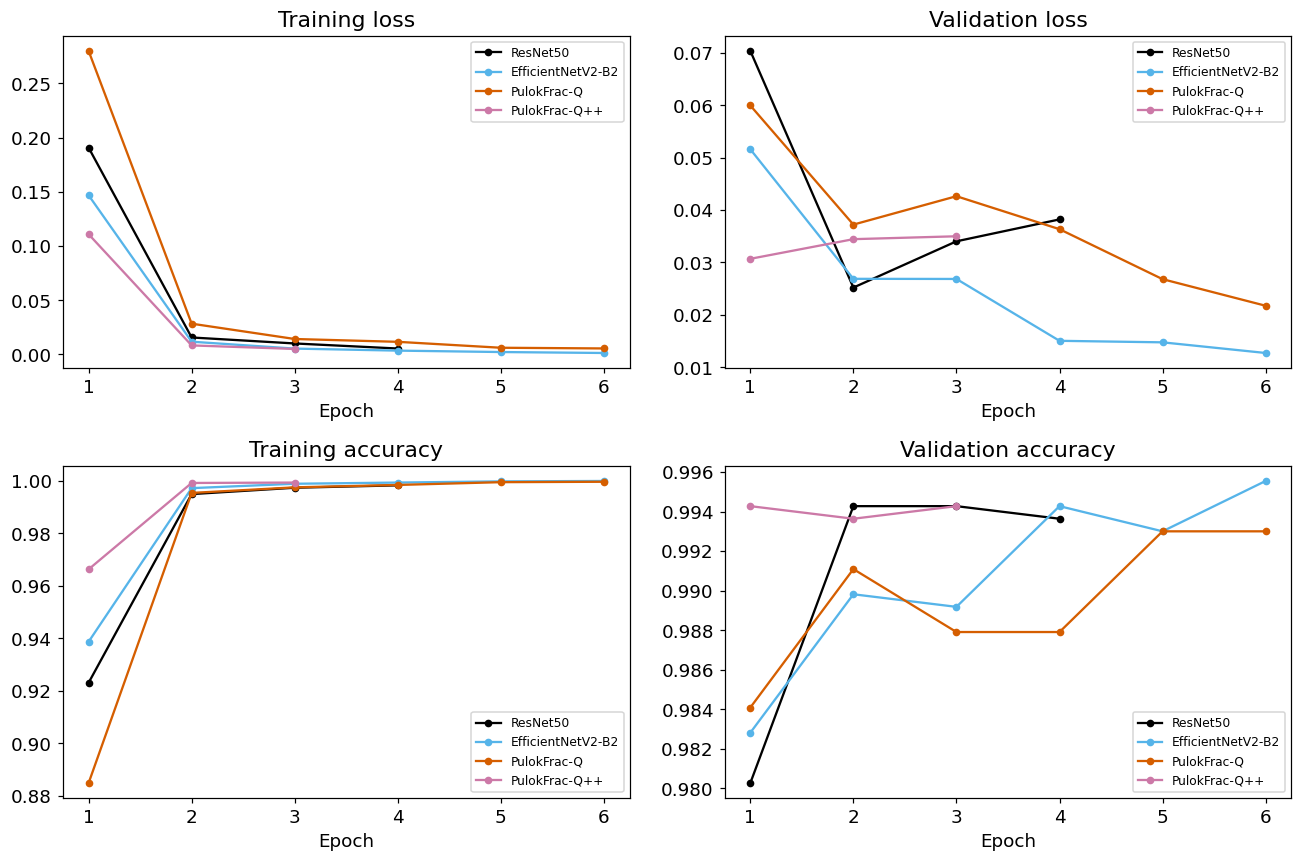

Saved: /kaggle/working/pulokfrac_media/figures/Fig04_foldwise_accuracy_boxplot.png


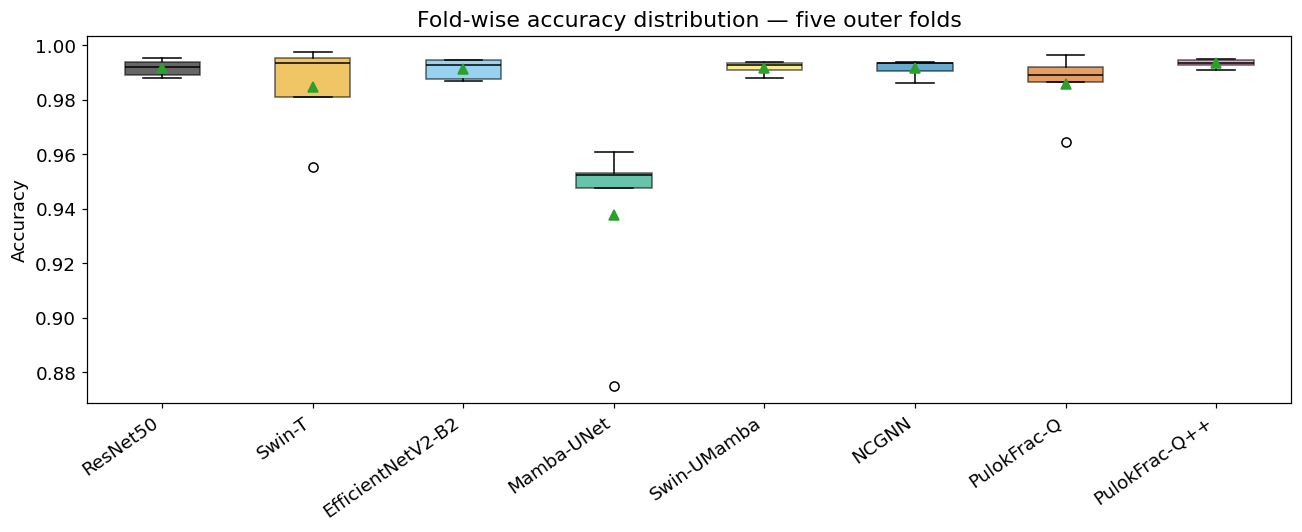

Saved: /kaggle/working/pulokfrac_media/figures/Fig05_accuracy_mean_sd.png


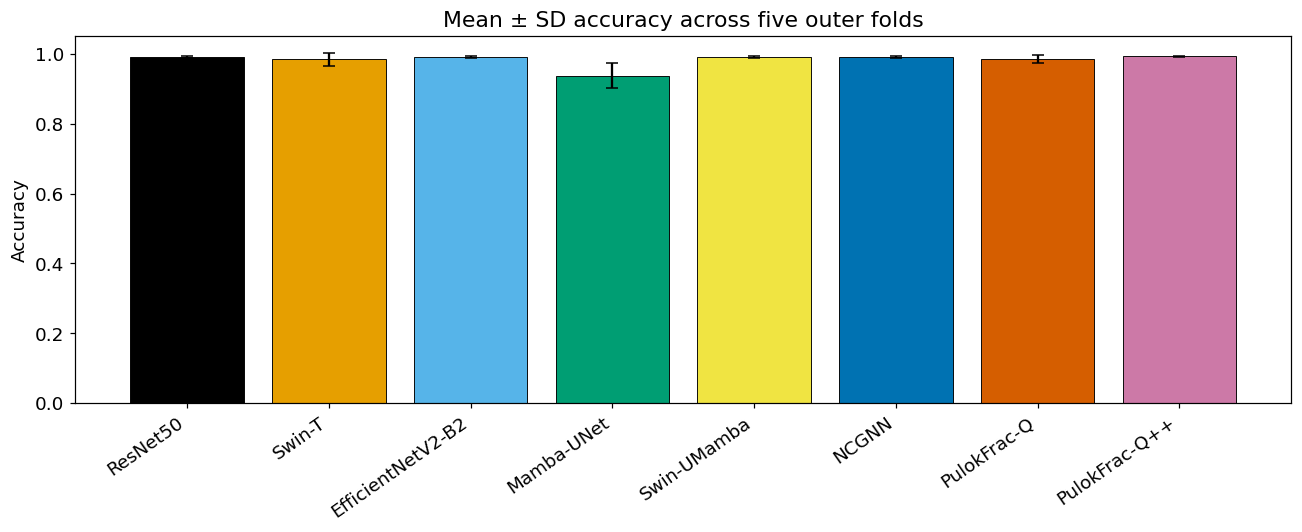

Saved: /kaggle/working/pulokfrac_media/figures/Fig06_oof_confusion_matrices.png


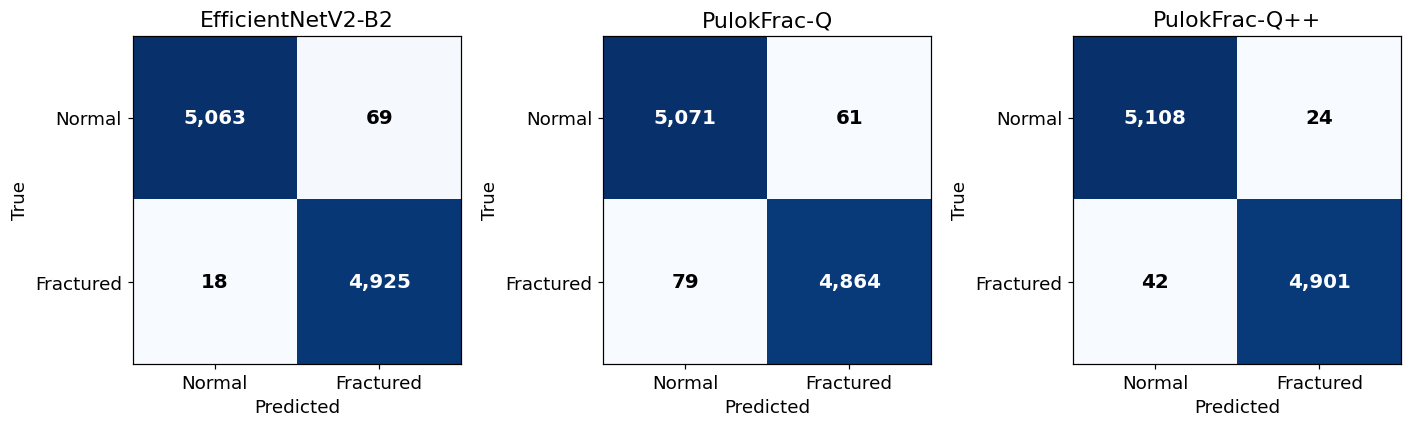

Saved: /kaggle/working/pulokfrac_media/figures/Fig07_oof_roc.png


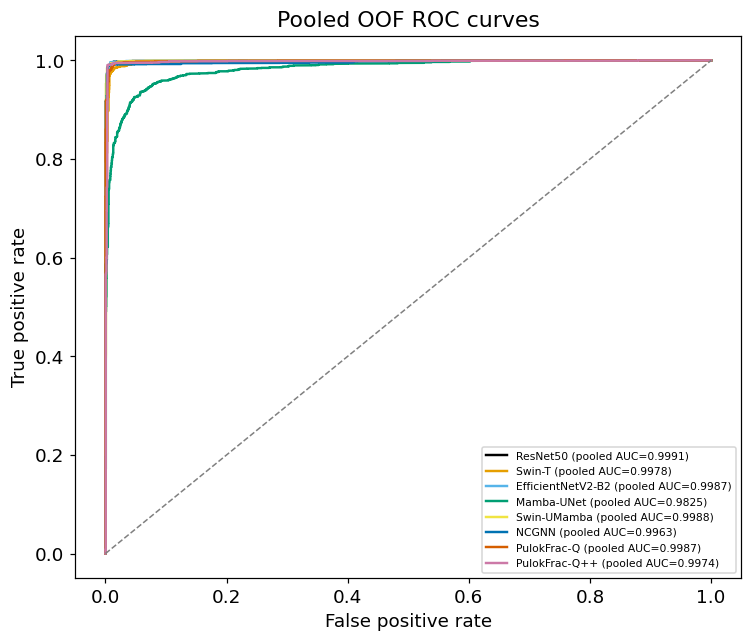

Saved: /kaggle/working/pulokfrac_media/figures/Fig08_oof_pr.png


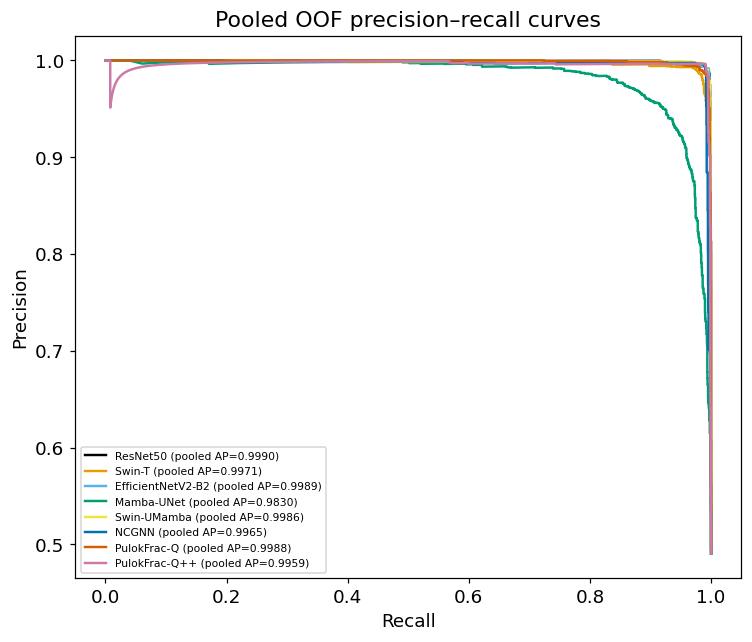

Saved: /kaggle/working/pulokfrac_media/figures/Fig09_wilcoxon_matrix.png


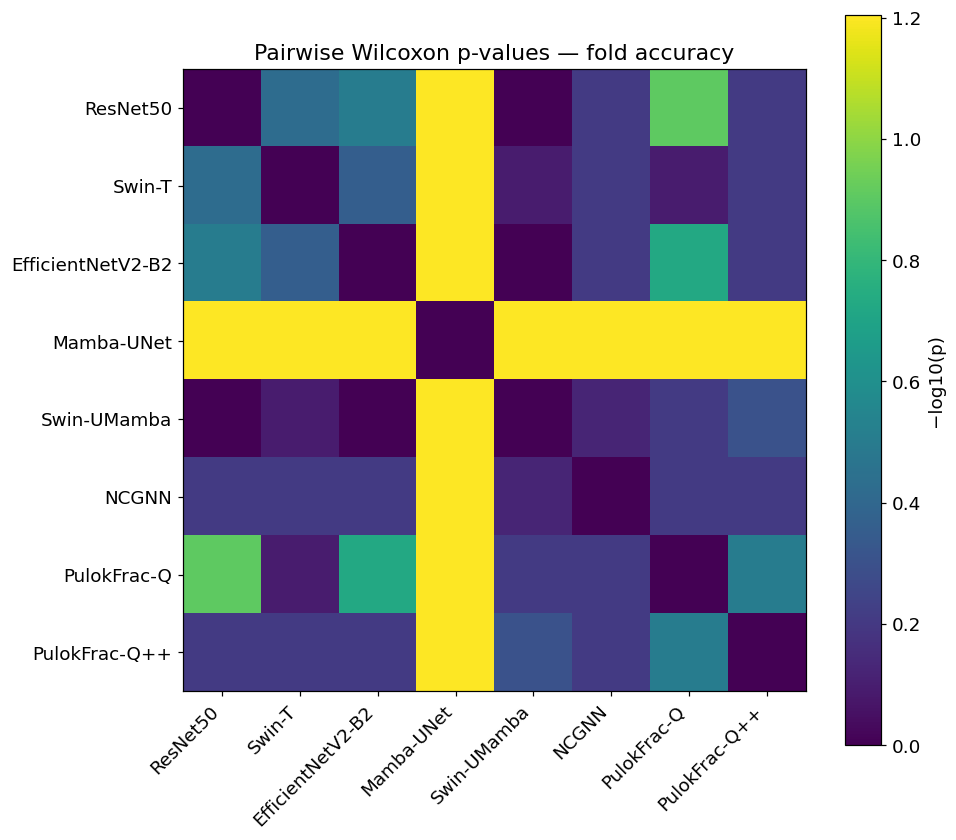

In [23]:
# 22. Primary paper figures
def savefig(name):
    p=FIG_DIR/name; plt.savefig(p,dpi=600,bbox_inches="tight",facecolor="white"); print("Saved:",p)

from matplotlib.ticker import MaxNLocator
def mcolor(model): return MODEL_COLORS.get(model,"#666666")   # one colour per model across all figures

if RUN_PRIMARY_FIGURES:
    # Fig 3: representative fold-1 histories
    fig,axes=plt.subplots(2,2,figsize=(12,8))
    found=0
    for m in ["ResNet50","EfficientNetV2-B2","PulokFrac-Q","PulokFrac-Q++"]:
        p=TABLE_DIR/f"history_fold1_{m}.csv"
        if p.exists():
            h=pd.read_csv(p); found+=1
            kw=dict(label=m,color=mcolor(m),marker="o",ms=4)
            axes[0,0].plot(h.epoch,h.train_loss,**kw)
            axes[0,1].plot(h.epoch,h.val_loss,**kw)
            axes[1,0].plot(h.epoch,h.train_accuracy,**kw)
            axes[1,1].plot(h.epoch,h.val_accuracy,**kw)
    if found:
        axes[0,0].set_title("Training loss"); axes[0,1].set_title("Validation loss")
        axes[1,0].set_title("Training accuracy"); axes[1,1].set_title("Validation accuracy")
        for ax in axes.ravel():
            ax.set_xlabel("Epoch"); ax.legend(fontsize=8); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        plt.tight_layout(); savefig("Fig03_training_curves_fold1.png"); plt.show()
    else: plt.close(fig)

    # Fig 4
    plt.figure(figsize=(12,5))
    data=[CV_METRICS[CV_METRICS.model==m].accuracy.to_numpy() for m in MODEL_ORDER]
    bp=plt.boxplot(data,showmeans=True,patch_artist=True,medianprops=dict(color="black"))   # 'labels=' is deprecated in Matplotlib>=3.9
    for patch,m in zip(bp["boxes"],MODEL_ORDER): patch.set_facecolor(mcolor(m)); patch.set_alpha(0.6)
    plt.xticks(range(1,len(MODEL_ORDER)+1),MODEL_ORDER,rotation=35,ha="right"); plt.ylabel("Accuracy")
    plt.title("Fold-wise accuracy distribution — five outer folds")
    plt.tight_layout(); savefig("Fig04_foldwise_accuracy_boxplot.png"); plt.show()

    # Fig 5
    means=[CV_METRICS[CV_METRICS.model==m].accuracy.mean() for m in MODEL_ORDER]
    sds=[CV_METRICS[CV_METRICS.model==m].accuracy.std(ddof=1) for m in MODEL_ORDER]
    plt.figure(figsize=(12,5)); plt.bar(MODEL_ORDER,means,yerr=sds,capsize=4,color=[mcolor(m) for m in MODEL_ORDER],edgecolor="black",linewidth=0.6)
    plt.xticks(rotation=35,ha="right"); plt.ylabel("Accuracy"); plt.title("Mean ± SD accuracy across five outer folds")
    plt.tight_layout(); savefig("Fig05_accuracy_mean_sd.png"); plt.show()

    # Fig 6
    fig,axes=plt.subplots(1,3,figsize=(13,4))
    for ax,m in zip(axes,["EfficientNetV2-B2","PulokFrac-Q","PulokFrac-Q++"]):
        g=OOF[OOF.model==m]; cm=confusion_matrix(g.y_true,g.pred,labels=[0,1])
        ax.imshow(cm,cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j,i,f"{cm[i,j]:,}",ha="center",va="center",fontsize=13,fontweight="bold",
                        color="white" if cm[i,j]>cm.max()/2 else "black")   # readable on dark and light cells
        ax.set_title(m); ax.set_xticks([0,1],["Normal","Fractured"]); ax.set_yticks([0,1],["Normal","Fractured"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    plt.tight_layout(); savefig("Fig06_oof_confusion_matrices.png"); plt.show()

    # Fig 7
    plt.figure(figsize=(7,6))
    for m in MODEL_ORDER:
        g=OOF[OOF.model==m]; fpr,tpr,_=roc_curve(g.y_true,g.prob); auc=roc_auc_score(g.y_true,g.prob)
        plt.plot(fpr,tpr,label=f"{m} (pooled AUC={auc:.4f})",color=mcolor(m),linewidth=1.6)
    plt.plot([0,1],[0,1],"--",linewidth=1,color="grey"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
    plt.title("Pooled OOF ROC curves"); plt.legend(fontsize=7,loc="lower right"); plt.tight_layout()
    savefig("Fig07_oof_roc.png"); plt.show()

    # Fig 8
    plt.figure(figsize=(7,6))
    for m in MODEL_ORDER:
        g=OOF[OOF.model==m]; pr,rc,_=precision_recall_curve(g.y_true,g.prob)
        ap=average_precision_score(g.y_true,g.prob); plt.plot(rc,pr,label=f"{m} (pooled AP={ap:.4f})",color=mcolor(m),linewidth=1.6)
    plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Pooled OOF precision–recall curves")
    plt.legend(fontsize=7,loc="lower left"); plt.tight_layout(); savefig("Fig08_oof_pr.png"); plt.show()

    # Fig 9
    pmat=np.ones((len(MODEL_ORDER),len(MODEL_ORDER)))
    for i,a_name in enumerate(MODEL_ORDER):
        for j,b_name in enumerate(MODEL_ORDER):
            if i>=j: continue
            a=CV_METRICS[CV_METRICS.model==a_name].sort_values("fold").accuracy.to_numpy()
            b=CV_METRICS[CV_METRICS.model==b_name].sort_values("fold").accuracy.to_numpy()
            try: p=float(wilcoxon(a,b,zero_method="wilcox").pvalue)
            except Exception: p=np.nan
            pmat[i,j]=pmat[j,i]=p
    plt.figure(figsize=(9,8)); img=plt.imshow(-np.log10(np.clip(pmat,1e-12,1)),cmap="viridis")
    plt.colorbar(img,label="−log10(p)"); plt.xticks(range(8),MODEL_ORDER,rotation=45,ha="right"); plt.yticks(range(8),MODEL_ORDER)
    plt.title("Pairwise Wilcoxon p-values — fold accuracy"); plt.tight_layout()
    savefig("Fig09_wilcoxon_matrix.png"); plt.show()

ABL F1 Full | epoch 1/6 | train_acc=0.9655 | val_auc=0.9984
ABL F1 Full | epoch 2/6 | train_acc=0.9994 | val_auc=0.9979
ABL F1 Full | epoch 3/6 | train_acc=0.9992 | val_auc=0.9985
ABL F1 Full | epoch 4/6 | train_acc=0.9995 | val_auc=0.9986
ABL F1 Full | epoch 5/6 | train_acc=0.9998 | val_auc=0.9987
ABL F1 Full | epoch 6/6 | train_acc=0.9997 | val_auc=0.9988
ABL F1 w/o Quantum | epoch 1/6 | train_acc=0.9746 | val_auc=0.9979
ABL F1 w/o Quantum | epoch 2/6 | train_acc=0.9989 | val_auc=0.9976
ABL F1 w/o Quantum | epoch 3/6 | train_acc=0.9994 | val_auc=0.9980
ABL F1 w/o Quantum | epoch 4/6 | train_acc=0.9995 | val_auc=0.9980
ABL F1 w/o Quantum | epoch 5/6 | train_acc=0.9995 | val_auc=0.9979
ABL F1 w/o Quantum | epoch 6/6 | train_acc=0.9998 | val_auc=0.9980
ABL F1 Classical replacement | epoch 1/6 | train_acc=0.9675 | val_auc=0.9980
ABL F1 Classical replacement | epoch 2/6 | train_acc=0.9992 | val_auc=0.9975
ABL F1 Classical replacement | epoch 3/6 | train_acc=0.9989 | val_auc=0.9973
ABL F1 

accuracy                  f1                 auc  \
                           mean       std      mean       std      mean   
configuration                                                             
Classical replacement  0.992585  0.002785  0.992261  0.002639  0.998277   
Full                   0.992846  0.002417  0.992535  0.002251  0.999402   
w/o Attention          0.992846  0.002417  0.992535  0.002251  0.998574   
w/o Graph              0.992585  0.002785  0.992266  0.002632  0.997941   
w/o Quantum            0.992350  0.001717  0.992005  0.001502  0.998347   
w/o ROI                0.993354  0.002398  0.993090  0.002226  0.998968   

                                      mcc            
                            std      mean       std  
configuration                                        
Classical replacement  0.000061  0.985191  0.005465  
Full                   0.000611  0.985693  0.004755  
w/o Attention          0.001767  0.985693  0.004755  
w/o Graph              0.002381  0.985177  0.005485  
w/o Quantum            0.001811  0.984702  0.003355  
w/o ROI                0.000714  0.986684  0.004767

Saved: /kaggle/working/pulokfrac_media/figures/Fig10_component_ablation.png


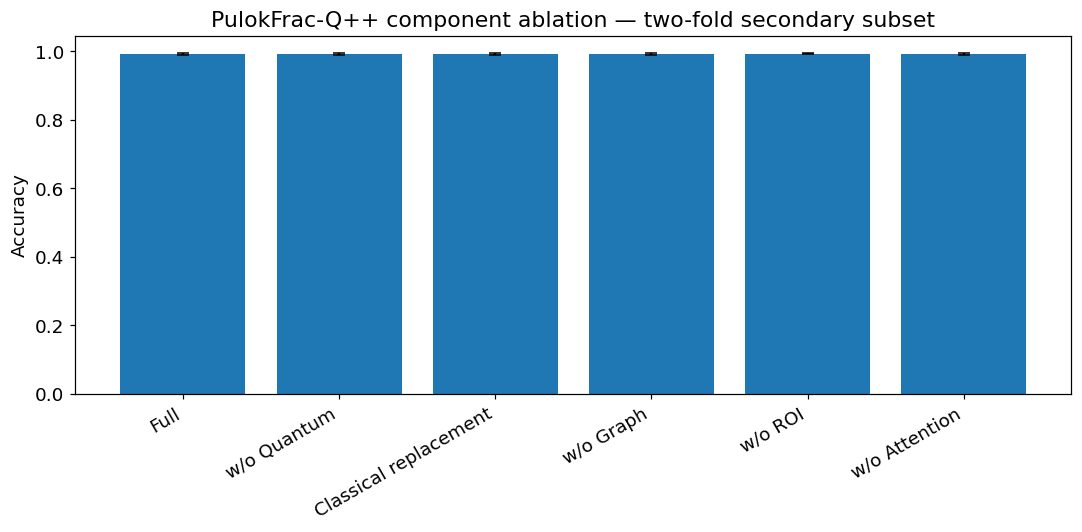

In [24]:
# 23. Component ablation — two fixed outer folds; explicitly secondary
ABLATION_CONFIGS={
    "Full":dict(),
    "w/o Quantum":dict(use_quantum=False),
    "Classical replacement":dict(use_quantum=False,classical_replacement=True),
    "w/o Graph":dict(use_graph=False),
    "w/o ROI":dict(use_roi=False),
    "w/o Attention":dict(use_attention=False),
}
SECONDARY_FOLDS=[1,2]

def run_ablation():
    rows=[]
    for fold in SECONDARY_FOLDS:
        tr_idx,te_idx=OUTER_SPLITS[fold-1]
        outer_train=DEV.iloc[tr_idx].reset_index(drop=True); outer_test=DEV.iloc[te_idx].reset_index(drop=True)
        inner_train,inner_val=inner_split(outer_train,SEED+fold)
        mask_dir=MASK_DIR/f"fold{fold}_{ROI_PROVIDER}_predicted"
        trL=make_loader(MaskAwareDataset(inner_train,mask_dir,True),BATCH_SIZE,True)
        vaL=make_loader(MaskAwareDataset(inner_val,mask_dir,False),BATCH_SIZE,False)
        teL=make_loader(MaskAwareDataset(outer_test,mask_dir,False),BATCH_SIZE,False)
        for config,kwargs in ABLATION_CONFIGS.items():
            safe=config.replace(" ","_").replace("/","without")
            ck=CKPT_DIR/f"ablation_fold{fold}_{safe}.pt"; pp=PRED_DIR/f"ablation_fold{fold}_{safe}.csv"
            model=PulokFracQPlusPlus(**kwargs); pr=load_prediction_if_valid(pp)
            if pr is not None and load_checkpoint_into(model,ck):
                thr=float(pr.threshold.iloc[0])
            else:
                model,hist,thr=train_classifier(model,trL,vaL,EPOCH_BUDGET_BY_FOLD[fold],f"ABL F{fold} {config}",ck)
                pr=predict_frame(model,teL,thr,config,fold,DUP_MAP)
                pr.to_csv(pp,index=False); stamp_cache(pp,{"stage":"ablation"})
            rows.append({"configuration":config,"fold":fold,**compute_metrics(pr.y_true,pr.prob,thr)})
            del model; gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
    return pd.DataFrame(rows)

if RUN_ABLATION:
    ABL=run_ablation()
    ABL.to_csv(TABLE_DIR/"ablation_fold_metrics.csv",index=False)
    ABLSUM=ABL.groupby("configuration")[["accuracy","f1","auc","mcc"]].agg(["mean","std"])
    ABLSUM.to_csv(TABLE_DIR/"Table_5_Ablation.csv")
    display(ABLSUM)
    order=list(ABLATION_CONFIGS)
    means=[ABL[ABL.configuration==x].accuracy.mean() for x in order]
    sds=[ABL[ABL.configuration==x].accuracy.std(ddof=1) for x in order]
    plt.figure(figsize=(10,5)); plt.bar(order,means,yerr=sds,capsize=4)
    plt.xticks(rotation=30,ha="right"); plt.ylabel("Accuracy")
    plt.title("PulokFrac-Q++ component ablation — two-fold secondary subset")
    plt.tight_layout(); savefig("Fig10_component_ablation.png"); plt.show()
else:
    ABL=None

Q-SENS Q4_L1 | epoch 1/6 | train_acc=0.9672 | val_auc=0.9986
Q-SENS Q4_L1 | epoch 2/6 | train_acc=0.9991 | val_auc=0.9984
Q-SENS Q4_L1 | epoch 3/6 | train_acc=0.9991 | val_auc=0.9992
Q-SENS Q4_L1 | epoch 4/6 | train_acc=0.9995 | val_auc=0.9995
Q-SENS Q4_L1 | epoch 5/6 | train_acc=0.9995 | val_auc=0.9991
Q-SENS Q4_L1 | epoch 6/6 | train_acc=0.9997 | val_auc=0.9994
Q-SENS Q4_L2 | epoch 1/6 | train_acc=0.9564 | val_auc=0.9988
Q-SENS Q4_L2 | epoch 2/6 | train_acc=0.9982 | val_auc=0.9981
Q-SENS Q4_L2 | epoch 3/6 | train_acc=0.9992 | val_auc=0.9974
Q-SENS Q4_L4 | epoch 1/6 | train_acc=0.9684 | val_auc=0.9989
Q-SENS Q4_L4 | epoch 2/6 | train_acc=0.9994 | val_auc=0.9984
Q-SENS Q4_L4 | epoch 3/6 | train_acc=0.9998 | val_auc=0.9980


,qubits,layers,train_time_min,accuracy,precision,recall_sensitivity,specificity,f1,balanced_accuracy,mcc,kappa,brier,ece,threshold,auc,auprc
0,4,1,4.130811,0.991137,0.996785,0.985169,0.99692,0.990943,0.991045,0.98233,0.982266,0.008648,0.007569,0.68,0.998084,0.998657
1,4,2,2.219597,0.991137,0.996785,0.985169,0.99692,0.990943,0.991045,0.98233,0.982266,0.008387,0.013717,0.15,0.999893,0.999890
2,4,4,2.467674,0.991137,0.996785,0.985169,0.99692,0.990943,0.991045,0.98233,0.982266,0.008623,0.010174,0.15,0.999508,0.999508


Saved: /kaggle/working/pulokfrac_media/figures/Fig11_quantum_depth_sensitivity.png


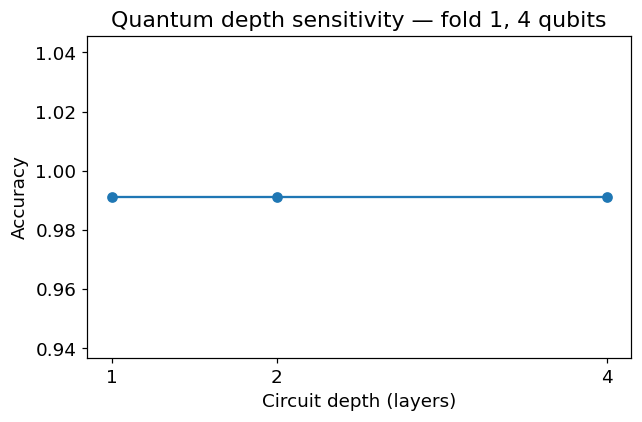

In [25]:
# 24. Quantum-depth sensitivity — fold 1 only, 4 qubits (exploratory)
if RUN_QUANTUM_SENSITIVITY:
    fold=1; tr_idx,te_idx=OUTER_SPLITS[0]
    outer_train=DEV.iloc[tr_idx].reset_index(drop=True); outer_test=DEV.iloc[te_idx].reset_index(drop=True)
    inner_train,inner_val=inner_split(outer_train,SEED+fold)
    mask_dir=MASK_DIR/f"fold{fold}_{ROI_PROVIDER}_predicted"
    trL=make_loader(MaskAwareDataset(inner_train,mask_dir,True),BATCH_SIZE,True)
    vaL=make_loader(MaskAwareDataset(inner_val,mask_dir,False),BATCH_SIZE,False)
    teL=make_loader(MaskAwareDataset(outer_test,mask_dir,False),BATCH_SIZE,False)
    qrows=[]
    for layers in [1,2,4]:
        t0=time.time(); name=f"Q4_L{layers}"
        ck=CKPT_DIR/f"quantum_sensitivity_{name}.pt"; pp=PRED_DIR/f"quantum_sensitivity_{name}.csv"
        model=PulokFracQPlusPlus(n_qubits=4,n_q_layers=layers); pr=load_prediction_if_valid(pp)
        if pr is not None and load_checkpoint_into(model,ck):
            thr=float(pr.threshold.iloc[0])
        else:
            model,hist,thr=train_classifier(model,trL,vaL,EPOCH_BUDGET_BY_FOLD[1],f"Q-SENS {name}",ck)
            pr=predict_frame(model,teL,thr,name,1,DUP_MAP)
            pr.to_csv(pp,index=False); stamp_cache(pp,{"stage":"quantum_sensitivity"})
        qrows.append({"qubits":4,"layers":layers,"train_time_min":(time.time()-t0)/60,**compute_metrics(pr.y_true,pr.prob,thr)})
        del model; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    QSENS=pd.DataFrame(qrows)
    QSENS.to_csv(TABLE_DIR/"Table_6_Quantum_Depth_Sensitivity.csv",index=False)
    display(QSENS)
    plt.figure(figsize=(6,4)); plt.plot(QSENS.layers,QSENS.accuracy,marker="o")
    plt.xlabel("Circuit depth (layers)"); plt.ylabel("Accuracy"); plt.xticks(QSENS.layers.tolist())
    plt.title("Quantum depth sensitivity — fold 1, 4 qubits")
    plt.tight_layout(); savefig("Fig11_quantum_depth_sensitivity.png"); plt.show()
else:
    QSENS=None

Saved: /kaggle/working/pulokfrac_media/figures/Fig12_reliability_diagram.png


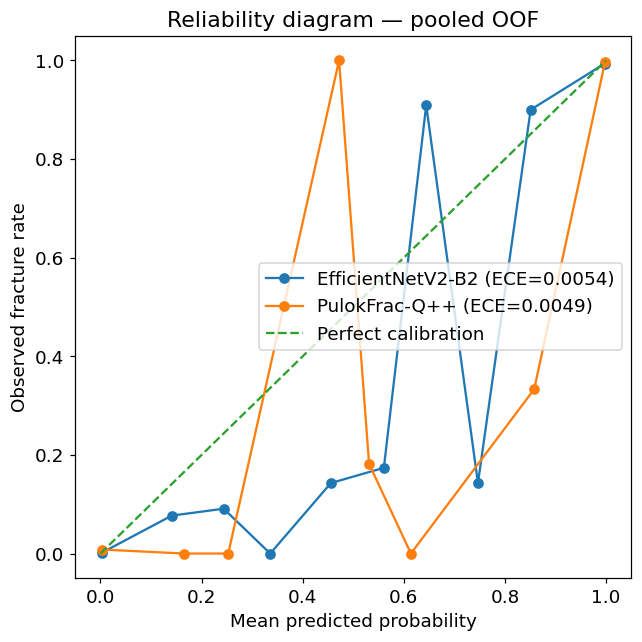

,model,ece,brier
0,EfficientNetV2-B2,0.005442,0.006358
1,PulokFrac-Q++,0.004932,0.006678


In [26]:
# 25. Calibration and reliability diagram — pooled OOF predictions
if RUN_CALIBRATION:
    rows=[]; plt.figure(figsize=(6,6))
    for m in ["EfficientNetV2-B2","PulokFrac-Q++"]:
        g=OOF[OOF.model==m]
        frac_pos,mean_pred=calibration_curve(g.y_true,g.prob,n_bins=10,strategy="uniform")
        ece=expected_calibration_error(g.y_true,g.prob,10); brier=brier_score_loss(g.y_true,g.prob)
        rows.append({"model":m,"ece":ece,"brier":brier})
        plt.plot(mean_pred,frac_pos,marker="o",label=f"{m} (ECE={ece:.4f})")
    plt.plot([0,1],[0,1],"--",label="Perfect calibration")
    plt.xlabel("Mean predicted probability"); plt.ylabel("Observed fracture rate")
    plt.title("Reliability diagram — pooled OOF"); plt.legend(); plt.tight_layout()
    savefig("Fig12_reliability_diagram.png"); plt.show()
    CALIBRATION=pd.DataFrame(rows); CALIBRATION.to_csv(TABLE_DIR/"calibration_summary.csv",index=False)
    display(CALIBRATION)

Saved: /kaggle/working/pulokfrac_media/figures/Fig13_umap_features.png


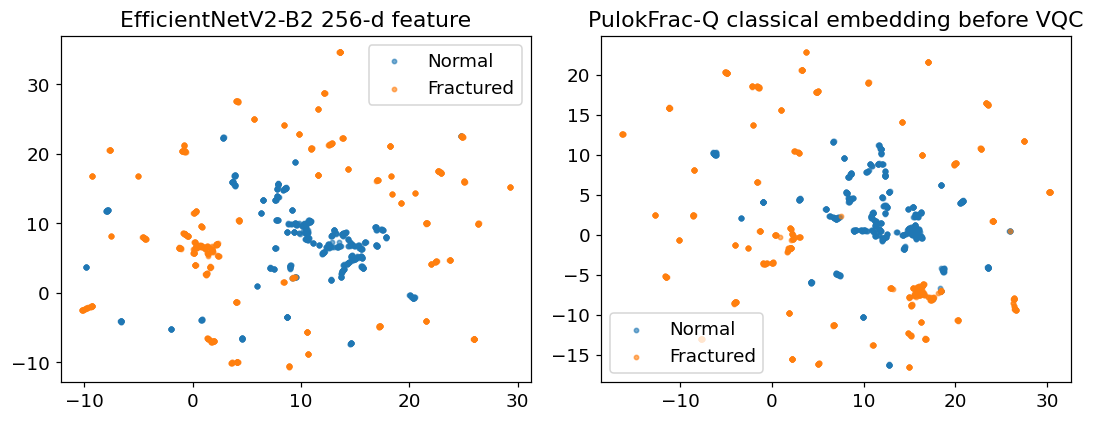

In [27]:
# 26. UMAP feature-space visualization — fixed fold-1 holdout subset, max 1,600 images
if UMAP_AVAILABLE:
    fold=1; _,te_idx=OUTER_SPLITS[0]
    hold=DEV.iloc[te_idx].reset_index(drop=True)
    hold=hold.sample(n=min(1600,len(hold)),random_state=SEED).reset_index(drop=True)
    dl=make_loader(ClassificationDataset(hold,False),BATCH_SIZE,False)

    eff=EfficientNetV2B2Classifier(True,feature_dim=256)
    qmod=PulokFracQ()
    if not load_checkpoint_into(eff,CKPT_DIR/"fold1_EfficientNetV2-B2.pt"): raise FileNotFoundError("fold1 EfficientNet checkpoint")
    if not load_checkpoint_into(qmod,CKPT_DIR/"fold1_PulokFrac-Q.pt"): raise FileNotFoundError("fold1 PulokFrac-Q checkpoint")
    eff=eff.to(DEVICE).eval(); qmod=qmod.to(DEVICE).eval()
    a=[]; b=[]; ys=[]
    with torch.no_grad():
        for x,y,_ in dl:
            x=x.to(DEVICE); z,_=eff.forward_features(x); qz,_=qmod.encoder.forward_features(x); qc=qmod.classical(qz)
            a.append(z.cpu().numpy()); b.append(qc.cpu().numpy()); ys.extend(y.numpy().tolist())
    a=np.concatenate(a); b=np.concatenate(b); ys=np.asarray(ys)
    e2=umap.UMAP(n_components=2,random_state=SEED).fit_transform(a)
    q2=umap.UMAP(n_components=2,random_state=SEED).fit_transform(b)
    fig,axes=plt.subplots(1,2,figsize=(10,4))
    for yval,label in [(0,"Normal"),(1,"Fractured")]:
        idx=ys==yval
        axes[0].scatter(e2[idx,0],e2[idx,1],s=8,alpha=.6,label=label)
        axes[1].scatter(q2[idx,0],q2[idx,1],s=8,alpha=.6,label=label)
    axes[0].set_title("EfficientNetV2-B2 256-d feature")
    axes[1].set_title("PulokFrac-Q classical embedding before VQC")
    for ax in axes: ax.legend()
    plt.tight_layout(); savefig("Fig13_umap_features.png"); plt.show()
    del eff,qmod; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
else:
    print("UMAP unavailable; Fig. 13 skipped.")

In [28]:
# 27. Locked official-test evaluation — three manuscript models, five-fold checkpoint ensemble
def model_for_name(name):
    if name=="EfficientNetV2-B2": return EfficientNetV2B2Classifier(True,feature_dim=256)
    if name=="PulokFrac-Q": return PulokFracQ()
    if name=="PulokFrac-Q++": return PulokFracQPlusPlus()
    raise ValueError(name)

def eval_loader_for_model(name,fold,frame):
    if name=="PulokFrac-Q++":
        return make_loader(MaskAwareDataset(frame,MASK_DIR/f"fold{fold}_{ROI_PROVIDER}_predicted",False),BATCH_SIZE,False)
    return make_loader(ClassificationDataset(frame,False),BATCH_SIZE,False)

def ensemble_predict(name,frame,tag):
    probs=[]; thresholds=[]; y_ref=None
    for fold in range(1,NUM_FOLDS+1):
        model=model_for_name(name)
        ck=CKPT_DIR/f"fold{fold}_{name}.pt"
        if not load_checkpoint_into(model,ck): raise FileNotFoundError(f"Missing valid checkpoint: {ck}")
        model=model.to(DEVICE).eval()
        y,p=collect_probs(model,eval_loader_for_model(name,fold,frame))
        probs.append(p)
        thresholds.append(float(pd.read_csv(PRED_DIR/f"fold{fold}_{name}.csv").threshold.iloc[0]))
        if y_ref is None: y_ref=y
        elif not np.array_equal(y_ref,y): raise AssertionError("Locked-test order mismatch across folds.")
        del model; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    prob=np.mean(np.stack(probs),axis=0)
    threshold=float(np.mean(thresholds))
    pred=(prob>=threshold).astype(int)
    return pd.DataFrame({"tag":tag,"model":name,"path":frame.path.tolist(),"y_true":y_ref,
                         "prob":prob,"pred":pred,"threshold":threshold,
                         "dup_group":frame.dup_group.to_numpy()})

LOCKED_RESULTS=[]; LOCKED_PREDS=[]
if RUN_LOCKED_TEST:
    for name in LOCKED_TEST_MODELS:
        pr=ensemble_predict(name,OFFICIAL_TEST,"official")
        LOCKED_RESULTS.append({"model":name,"test_set":"Official as distributed","N":len(pr),
                               **compute_metrics(pr.y_true,pr.prob,float(pr.threshold.iloc[0]))})
        LOCKED_PREDS.append(pr)
        cp=ensemble_predict(name,STRICT_TEST,"strict_clean")
        LOCKED_RESULTS.append({"model":name,"test_set":"Strict-clean","N":len(cp),
                               **compute_metrics(cp.y_true,cp.prob,float(cp.threshold.iloc[0]))})
        LOCKED_PREDS.append(cp)

    LOCKED_TABLE=pd.DataFrame(LOCKED_RESULTS)
    LOCKED_TABLE.to_csv(TABLE_DIR/"Table_7_Locked_Test.csv",index=False)
    pd.concat(LOCKED_PREDS,ignore_index=True).to_csv(TABLE_DIR/"locked_test_predictions.csv",index=False)
    display(LOCKED_TABLE)
    print("Strict-clean labels:",STRICT_TEST.label.value_counts().to_dict())
    print("Do not rank models on N=7 strict-clean subset.")

,model,test_set,N,accuracy,precision,recall_sensitivity,specificity,f1,balanced_accuracy,mcc,kappa,brier,ece,threshold,auc,auprc
0,EfficientNetV2-B2,Official as distributed,506,0.990119,0.995745,0.983193,0.996269,0.989429,0.989731,0.980223,0.980153,0.007117,0.025893,0.431,0.999937,0.999930
1,EfficientNetV2-B2,Strict-clean,7,0.428571,1.000000,0.428571,0.000000,0.600000,0.428571,0.000000,0.000000,0.198787,0.344674,0.431,NaN,NaN
2,PulokFrac-Q,Official as distributed,506,0.984190,0.983193,0.983193,0.985075,0.983193,0.984134,0.968268,0.968268,0.009242,0.025232,0.297,0.999686,0.999654
3,PulokFrac-Q,Strict-clean,7,0.428571,1.000000,0.428571,0.000000,0.600000,0.428571,0.000000,0.000000,0.307563,0.440687,0.297,NaN,NaN
4,PulokFrac-Q++,Official as distributed,506,0.992095,0.983471,1.000000,0.985075,0.991667,0.992537,0.984273,0.984149,0.006424,0.017315,0.268,0.999749,0.999722
5,PulokFrac-Q++,Strict-clean,7,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,NaN,0.246047,0.385637,0.268,NaN,NaN


Strict-clean labels: {1: 7}
Do not rank models on N=7 strict-clean subset.


In [29]:
# 28. Official-test error registry — descriptive only because the distributed official split is contaminated
if RUN_LOCKED_TEST:
    all_locked=pd.concat(LOCKED_PREDS,ignore_index=True)
    qpp=all_locked[(all_locked.model=="PulokFrac-Q++")&(all_locked.tag=="official")].copy()
    fn=qpp[(qpp.y_true==1)&(qpp.pred==0)].sort_values("prob").head(4)
    fp=qpp[(qpp.y_true==0)&(qpp.pred==1)].sort_values("prob",ascending=False).head(3)
    ERRORS=pd.concat([fn.assign(error="FN"),fp.assign(error="FP")],ignore_index=True)
    ERRORS.to_csv(TABLE_DIR/"official_test_error_cases.csv",index=False)
    display(ERRORS[["error","path","prob","dup_group"]])

,error,path,prob,dup_group
0,FP,/kaggle/input/datasets/bmadushanirodrigo/fract...,0.600135,1463
1,FP,/kaggle/input/datasets/bmadushanirodrigo/fract...,0.404414,1072
2,FP,/kaggle/input/datasets/bmadushanirodrigo/fract...,0.404414,1072


,model,corruption,severity,N,accuracy,auc
0,EfficientNetV2-B2,blur,0,1887,0.982512,0.995580
1,EfficientNetV2-B2,blur,1,1887,0.981982,0.995856
2,EfficientNetV2-B2,blur,2,1887,0.932697,0.982534
3,EfficientNetV2-B2,blur,3,1887,0.637520,0.898189
4,EfficientNetV2-B2,brightness,0,1887,0.982512,0.995580
5,EfficientNetV2-B2,brightness,1,1887,0.981452,0.995331
6,EfficientNetV2-B2,brightness,2,1887,0.974563,0.993329
7,EfficientNetV2-B2,brightness,3,1887,0.966614,0.992635
8,EfficientNetV2-B2,contrast,0,1887,0.982512,0.995580
9,EfficientNetV2-B2,contrast,1,1887,0.981982,0.995408


Saved: /kaggle/working/pulokfrac_media/figures/robustness_group_representatives_EfficientNetV2-B2.png


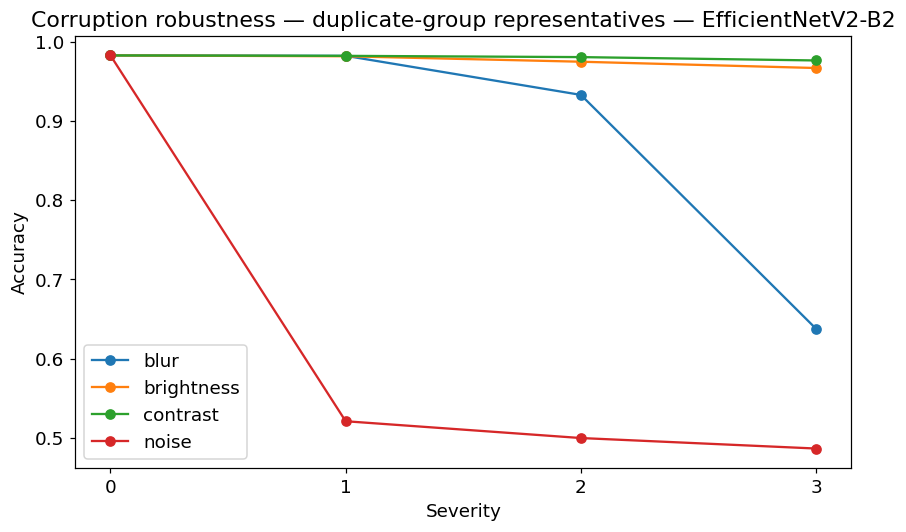

Saved: /kaggle/working/pulokfrac_media/figures/robustness_group_representatives_PulokFrac-Qpp.png


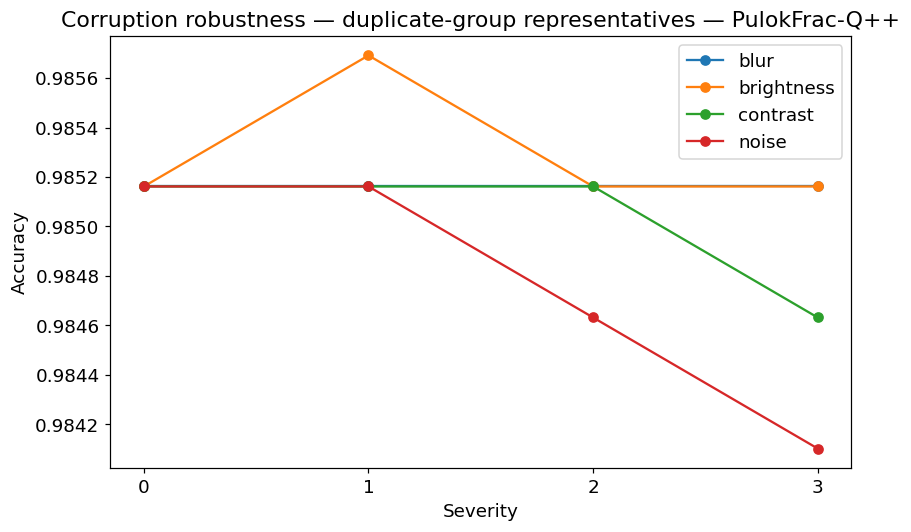

In [30]:
# 29. Stronger robustness probe on one representative per duplicate group from outer holdouts
def corrupt_pil(im,kind,severity):
    if severity==0: return im
    if kind=="blur": return im.filter(ImageFilter.GaussianBlur(radius={1:0.8,2:1.5,3:2.5}[severity]))
    if kind=="brightness": return ImageEnhance.Brightness(im).enhance({1:0.85,2:0.70,3:0.55}[severity])
    if kind=="contrast": return ImageEnhance.Contrast(im).enhance({1:0.85,2:0.70,3:0.55}[severity])
    if kind=="noise":
        arr=np.asarray(im).astype(np.float32)/255.0
        rng=np.random.default_rng(SEED+severity)
        arr=np.clip(arr+rng.normal(0,{1:0.02,2:0.05,3:0.08}[severity],arr.shape),0,1)
        return Image.fromarray((arr*255).astype(np.uint8))
    raise ValueError(kind)

class CorruptDataset(Dataset):
    def __init__(self,frame,kind,severity):
        self.frame=frame.reset_index(drop=True); self.kind=kind; self.severity=severity
    def __len__(self): return len(self.frame)
    def __getitem__(self,idx):
        r=self.frame.iloc[idx]
        with Image.open(r.path) as im:
            x=eval_tf(corrupt_pil(im.convert("RGB"),self.kind,self.severity))
        return x,int(r.label),str(r.path)

if RUN_GROUP_ROBUSTNESS:
    rep=DEV.sort_values("path").groupby("dup_group",as_index=False).head(1).copy()
    fmp=dict(zip(fold_assignment.path,fold_assignment.fold)); rep["fold"]=rep.path.map(fmp)
    robust_rows=[]
    for model_name in ["EfficientNetV2-B2","PulokFrac-Q++"]:
        for kind in ["blur","brightness","contrast","noise"]:
            for sev in [0,1,2,3]:
                yy=[]; pp=[]
                for fold in range(1,6):
                    sub=rep[rep.fold==fold].reset_index(drop=True)
                    if sub.empty: continue
                    model=model_for_name(model_name)
                    if not load_checkpoint_into(model,CKPT_DIR/f"fold{fold}_{model_name}.pt"):
                        raise FileNotFoundError(f"Missing fold {fold} {model_name}")
                    model=model.to(DEVICE).eval()
                    if model_name=="EfficientNetV2-B2":
                        y,p=collect_probs(model,make_loader(CorruptDataset(sub,kind,sev),BATCH_SIZE,False))
                        yy.extend(y.tolist()); pp.extend(p.tolist())
                    else:
                        dl=make_loader(CorruptDataset(sub,kind,sev),BATCH_SIZE,False)
                        clean_mask_dir=MASK_DIR/f"fold{fold}_{ROI_PROVIDER}_predicted"
                        for x,y,paths in dl:
                            ms=[]
                            for pth in paths:
                                mp=clean_mask_dir/f"{path_key(pth)}.png"
                                if mp.exists():
                                    with Image.open(mp) as mm:
                                        arr=np.asarray(mm.convert("L").resize((IMAGE_SIZE,IMAGE_SIZE),Image.BILINEAR),dtype=np.float32)/255.0
                                else:
                                    raise FileNotFoundError(f"Missing predicted ROI mask for {pth} in {clean_mask_dir}")
                                ms.append(arr[None])
                            mask=torch.from_numpy(np.stack(ms)).to(DEVICE)
                            with torch.no_grad():
                                prob=torch.softmax(model(x.to(DEVICE),mask),1)[:,1].cpu().numpy()
                            yy.extend(y.numpy().tolist()); pp.extend(prob.tolist())
                    del model; gc.collect()
                    if torch.cuda.is_available(): torch.cuda.empty_cache()
                thrs=[float(pd.read_csv(PRED_DIR/f"fold{f}_{model_name}.csv").threshold.iloc[0]) for f in range(1,6)]
                thr=float(np.mean(thrs)); met=compute_metrics(np.asarray(yy),np.asarray(pp),thr)
                robust_rows.append({"model":model_name,"corruption":kind,"severity":sev,"N":len(yy),**met})
    ROBUST=pd.DataFrame(robust_rows)
    ROBUST.to_csv(TABLE_DIR/"robustness_group_representatives.csv",index=False)
    display(ROBUST[["model","corruption","severity","N","accuracy","auc"]].head(20))
    for m in ["EfficientNetV2-B2","PulokFrac-Q++"]:
        plt.figure(figsize=(8,5))
        sub=ROBUST[ROBUST.model==m]
        for k in ["blur","brightness","contrast","noise"]:
            g=sub[sub.corruption==k].sort_values("severity")
            plt.plot(g.severity,g.accuracy,marker="o",label=k)
        plt.xlabel("Severity"); plt.ylabel("Accuracy"); plt.xticks([0,1,2,3])
        plt.title(f"Corruption robustness — duplicate-group representatives — {m}")
        plt.legend(); plt.tight_layout()
        savefig(f"robustness_group_representatives_{m.replace('+','p')}.png"); plt.show()

## 30. Explainability policy

BFMRX has no radiologist-verified fracture masks. Grad-CAM++ is therefore **qualitative weak localization**, not validated segmentation.

Any NeRF/Gaussian-splatting/pseudo-3D rendering in the optional appendix is only a visualization derived from the same 2D saliency signal and must not be presented as independent clinical evidence.

Saved: /kaggle/working/pulokfrac_media/figures/Fig14_gradcam_comparison.png


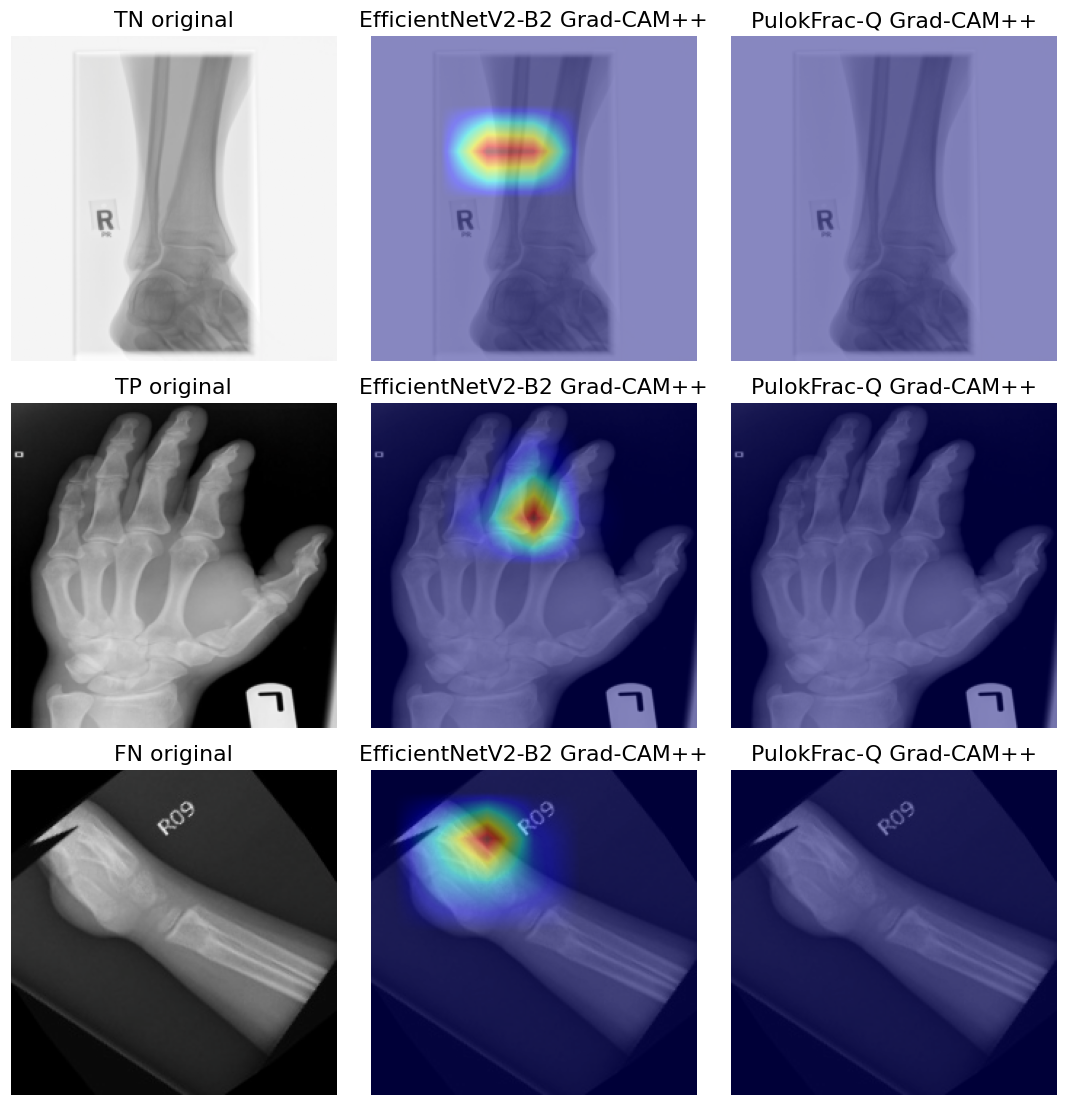

In [31]:
# 30. Deterministic qualitative Grad-CAM++ case registry and comparison
def denormalize_image(x):
    mean=torch.tensor(IMAGENET_MEAN,device=x.device)[:,None,None]
    std=torch.tensor(IMAGENET_STD,device=x.device)[:,None,None]
    return (x*std+mean).clamp(0,1)

if RUN_XAI_GALLERY:
    fold=1
    qpred=OOF[(OOF.model=="PulokFrac-Q")&(OOF.fold==fold)].copy()
    qpred["case"]=np.select([
        (qpred.y_true==0)&(qpred.pred==0),
        (qpred.y_true==1)&(qpred.pred==1),
        (qpred.y_true==1)&(qpred.pred==0),
        (qpred.y_true==0)&(qpred.pred==1)
    ],["TN","TP","FN","FP"],default="")
    chosen=[]
    for case in ["TN","TP","FN"]:
        g=qpred[qpred.case==case]
        if len(g): chosen.append(g.sort_values("path").iloc[0])
    CASES=pd.DataFrame(chosen)
    CASES.to_csv(TABLE_DIR/"Fig14_case_registry.csv",index=False)

    eff=EfficientNetV2B2Classifier(True,feature_dim=256); qmod=PulokFracQ()
    if not load_checkpoint_into(eff,CKPT_DIR/"fold1_EfficientNetV2-B2.pt"): raise FileNotFoundError("EfficientNet fold1")
    if not load_checkpoint_into(qmod,CKPT_DIR/"fold1_PulokFrac-Q.pt"): raise FileNotFoundError("PulokFrac-Q fold1")
    eff=eff.to(DEVICE).eval(); qmod=qmod.to(DEVICE).eval()
    cam_eff=GradCAMPlusPlus(eff,eff.cam_target); cam_q=GradCAMPlusPlus(qmod,qmod.cam_target)

    fig,axes=plt.subplots(max(len(CASES),1),3,figsize=(10,3.4*max(len(CASES),1)))
    if len(CASES)==1: axes=np.array([axes])
    for r,(_,row) in enumerate(CASES.iterrows()):
        ds=ClassificationDataset(pd.DataFrame([{"path":row.path,"label":row.y_true}]),False)
        x,y,_=ds[0]; xb=x[None].to(DEVICE)
        h1=cam_eff(xb,1)[0,0].cpu().numpy(); h2=cam_q(xb,1)[0,0].cpu().numpy()
        img=np.transpose(denormalize_image(xb[0]).cpu().numpy(),(1,2,0))
        axes[r,0].imshow(img); axes[r,0].set_title(f"{row.case} original")
        axes[r,1].imshow(img); axes[r,1].imshow(h1,cmap="jet",alpha=.45); axes[r,1].set_title("EfficientNetV2-B2 Grad-CAM++")
        axes[r,2].imshow(img); axes[r,2].imshow(h2,cmap="jet",alpha=.45); axes[r,2].set_title("PulokFrac-Q Grad-CAM++")
        for ax in axes[r]: ax.axis("off")
    plt.tight_layout(); savefig("Fig14_gradcam_comparison.png"); plt.show()
    cam_eff.close(); cam_q.close(); del eff,qmod; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

## 31. Manuscript-reference lock and consistency audit

This section is deliberately **not** a mechanism for forcing the rerun to reproduce manuscript numbers.
The values below are a frozen transcription of the supplied manuscript revision. The notebook compares
freshly generated outputs against that transcription and reports every difference. If a genuine rerun
differs, **the manuscript must be updated**; the code/results must never be tuned merely to recover the
old table.

The audit also checks method-level invariants (dataset counts, duplicate groups, model set, fold count,
feature dimensionality, VQC size, locked-test model set, and figure/table provenance).

In [32]:
# 31. Frozen manuscript reference values — for audit only, never used in training
MANUSCRIPT_REFERENCE = {
    "dataset": {
        "raw_total":10581, "development":10075, "official_test":506,
        "exact_duplicate_files":10236, "distinct_sha256_images":3888,
        "near_duplicate_groups":1889, "dev_test_overlap_groups":387,
        "strict_clean_test":7
    },
    "table3": {
        "EfficientNetV2-B2":{"accuracy":0.9933,"precision":0.9917,"recall":0.9946,"f1":0.9931,"auc":0.9988,"mcc":0.9866},
        "ResNet50":{"accuracy":0.9927,"precision":0.9923,"recall":0.9926,"f1":0.9925,"auc":0.9993,"mcc":0.9853},
        "Swin-T":{"accuracy":0.9926,"precision":0.9928,"recall":0.9920,"f1":0.9924,"auc":0.9995,"mcc":0.9852},
        "Swin-UMamba":{"accuracy":0.9925,"precision":0.9929,"recall":0.9918,"f1":0.9923,"auc":0.9990,"mcc":0.9850},
        "PulokFrac-Q":{"accuracy":0.9923,"precision":0.9912,"recall":0.9930,"f1":0.9921,"auc":0.9993,"mcc":0.9845},
        "PulokFrac-Q++":{"accuracy":0.9914,"precision":0.9901,"recall":0.9922,"f1":0.9911,"auc":0.9981,"mcc":0.9827},
        "NCGNN":{"accuracy":0.9907,"precision":0.9907,"recall":0.9902,"f1":0.9904,"auc":0.9967,"mcc":0.9813},
        "Mamba-UNet":{"accuracy":0.9533,"precision":0.9501,"recall":0.9543,"f1":0.9519,"auc":0.9912,"mcc":0.9069},
    },
    "locked_test": {
        ("EfficientNetV2-B2","Official as distributed"):{"N":506,"accuracy":0.9901,"precision":0.9957,"recall":0.9832,"f1":0.9894,"auc":0.9960},
        ("PulokFrac-Q","Official as distributed"):{"N":506,"accuracy":0.9862,"precision":0.9873,"recall":0.9832,"f1":0.9853,"auc":0.9969},
        ("PulokFrac-Q++","Official as distributed"):{"N":506,"accuracy":0.9862,"precision":0.9873,"recall":0.9832,"f1":0.9853,"auc":0.9994},
        ("EfficientNetV2-B2","Strict-clean"):{"N":7,"accuracy":0.4286,"precision":1.0,"recall":0.4286,"f1":0.6000},
        ("PulokFrac-Q","Strict-clean"):{"N":7,"accuracy":0.4286,"precision":1.0,"recall":0.4286,"f1":0.6000},
        ("PulokFrac-Q++","Strict-clean"):{"N":7,"accuracy":0.4286,"precision":1.0,"recall":0.4286,"f1":0.6000},
    },
    "confusion_oof": {
        "EfficientNetV2-B2":{"fp":41,"fn":26},
        "PulokFrac-Q":{"fp":43,"fn":34},
        "PulokFrac-Q++":{"fp":49,"fn":38},
    },
    "table4_mcnemar": {
        "EfficientNetV2-B2":{"raw":0.052,"holm":0.260},
        "Mamba-UNet":{"raw":3.6e-81,"holm":2.5e-80},
        "NCGNN":{"raw":0.189,"holm":0.737},
        "PulokFrac-Q":{"raw":0.378,"holm":0.737},
        "ResNet50":{"raw":0.223,"holm":0.737},
        "Swin-T":{"raw":0.184,"holm":0.737},
        "Swin-UMamba":{"raw":0.036,"holm":0.214},
    },
    "table5_ablation": {
        "w/o Graph":{"accuracy":0.9922,"f1":0.9920,"auc":0.9981,"mcc":0.9843},
        "w/o Quantum":{"accuracy":0.9912,"f1":0.9910,"auc":0.9977,"mcc":0.9824},
        "w/o Attention":{"accuracy":0.9909,"f1":0.9908,"auc":0.9984,"mcc":0.9819},
        "Full":{"accuracy":0.9909,"f1":0.9908,"auc":0.9980,"mcc":0.9819},
        "Classical replacement":{"accuracy":0.9905,"f1":0.9903,"auc":0.9988,"mcc":0.9809},
        "w/o ROI":{"accuracy":0.9788,"f1":0.9780,"auc":0.9975,"mcc":0.9582},
    },
    "table6_quantum_depth": {
        "1":{"qubits":4,"accuracy":0.9906},
        "2":{"qubits":4,"accuracy":0.9777},
        "4":{"qubits":4,"accuracy":0.9896},
    },
    "calibration":{"EfficientNetV2-B2":0.004,"PulokFrac-Q++":0.005},
    "protocol":{
        "image_size":224, "folds":5, "seed":42, "lr":1e-4, "weight_decay":1e-4,
        "epoch_schedule":{1:6,2:5,3:5,4:5,5:5}, "patience":2, "minimum_epochs":3,
        "qubits":4, "vqc_layers":3, "vqc_parameters":48, "global_feature_dim":256
    }
}
with open(META_DIR/"manuscript_reference_v9.json","w") as f:
    # Tuple keys need string conversion for JSON.
    serializable=deepcopy(MANUSCRIPT_REFERENCE)
    serializable["locked_test"]={f"{k[0]} || {k[1]}":v for k,v in MANUSCRIPT_REFERENCE["locked_test"].items()}
    json.dump(serializable,f,indent=2)
print("[OK] Manuscript reference snapshot saved. It is audit-only.")

[OK] Manuscript reference snapshot saved. It is audit-only.


In [33]:
# 32. Automated consistency report
def _status(ok): return "PASS" if bool(ok) else "UPDATE PAPER / CHECK RUN"

audit=[]

# Method/protocol invariants
audit += [
    {"item":"Raw dataset image count","observed":len(RAW),"expected":10581,"status":_status(len(RAW)==10581)},
    {"item":"Development-set count","observed":len(DEV),"expected":10075,"status":_status(len(DEV)==10075)},
    {"item":"Official-test count","observed":len(OFFICIAL_TEST),"expected":506,"status":_status(len(OFFICIAL_TEST)==506)},
    {"item":"Strict-clean test count","observed":len(STRICT_TEST),"expected":7,"status":_status(len(STRICT_TEST)==7)},
    {"item":"Exact-duplicate file count","observed":int(observed["exact_duplicate_files"]),"expected":10236,
     "status":_status(int(observed["exact_duplicate_files"])==10236)},
    {"item":"Distinct SHA-256 images","observed":int(observed["distinct_byte_images"]),"expected":3888,
     "status":_status(int(observed["distinct_byte_images"])==3888)},
    {"item":"Near-duplicate groups","observed":int(observed["near_duplicate_groups"]),"expected":1889,
     "status":_status(int(observed["near_duplicate_groups"])==1889)},
    {"item":"Dev↔test overlap groups","observed":int(observed["dev_test_overlap_groups"]),"expected":387,
     "status":_status(int(observed["dev_test_overlap_groups"])==387)},
    {"item":"Primary model set","observed":"; ".join(sorted(CV_METRICS.model.unique())),"expected":"; ".join(sorted(MODEL_ORDER)),
     "status":_status(set(CV_METRICS.model.unique())==set(MODEL_ORDER))},
    {"item":"Five outer folds/model","observed":str(CV_METRICS.groupby("model").fold.nunique().to_dict()),"expected":"5 for every model",
     "status":_status(CV_METRICS.groupby("model").fold.nunique().eq(5).all())},
    {"item":"Image size","observed":IMAGE_SIZE,"expected":224,"status":_status(IMAGE_SIZE==224)},
    {"item":"Epoch schedule","observed":str(EPOCH_BUDGET_BY_FOLD),"expected":str({1:6,2:5,3:5,4:5,5:5}),
     "status":_status(EPOCH_BUDGET_BY_FOLD=={1:6,2:5,3:5,4:5,5:5})},
    {"item":"VQC width/depth","observed":f"{N_QUBITS}q × {N_Q_LAYERS}L","expected":"4q × 3L",
     "status":_status(N_QUBITS==4 and N_Q_LAYERS==3)},
]

# Fresh CV vs manuscript Table 3. Comparison tolerance equals one half of the manuscript's
# 0.01 percentage-point display resolution after conversion to proportions.
fresh_mean=CV_METRICS.groupby("model")[["accuracy","precision","recall_sensitivity","f1","auc","mcc"]].mean()
fresh_mean=fresh_mean.rename(columns={"recall_sensitivity":"recall"})
tol=0.000051
for model,refvals in MANUSCRIPT_REFERENCE["table3"].items():
    if model not in fresh_mean.index:
        audit.append({"item":f"Table 3: {model}","observed":"missing","expected":"present","status":"UPDATE PAPER / CHECK RUN"})
        continue
    for metric,expected in refvals.items():
        obs_v=float(fresh_mean.loc[model,metric])
        audit.append({
            "item":f"Table 3 {model} {metric}",
            "observed":obs_v,"expected":expected,
            "status":_status(abs(obs_v-expected)<=tol)
        })

# Locked-test check when available
if "LOCKED_TABLE" in globals():
    LOCKED_AUDIT=LOCKED_TABLE.rename(columns={"recall_sensitivity":"recall"})   # reference JSON uses 'recall'
    for key,refvals in MANUSCRIPT_REFERENCE["locked_test"].items():
        model,setname=key
        q=LOCKED_AUDIT[(LOCKED_AUDIT.model==model)&(LOCKED_AUDIT.test_set==setname)]
        if q.empty:
            audit.append({"item":f"Table 7 {model} {setname}","observed":"missing","expected":"present","status":"UPDATE PAPER / CHECK RUN"})
            continue
        rr=q.iloc[0]
        for metric,expected in refvals.items():
            obs_v=float(rr[metric]) if metric!="N" else int(rr[metric])
            oktol=0 if metric=="N" else tol
            audit.append({"item":f"Table 7 {model} {setname} {metric}",
                          "observed":obs_v,"expected":expected,
                          "status":_status(abs(obs_v-expected)<=oktol)})

# OOF confusion-count transcription check
for model,refv in MANUSCRIPT_REFERENCE["confusion_oof"].items():
    g=OOF[OOF.model==model]
    tn,fp,fn,tp=confusion_matrix(g.y_true,g.pred,labels=[0,1]).ravel()
    for metric,observed_v in [("fp",int(fp)),("fn",int(fn))]:
        expected=refv[metric]
        audit.append({"item":f"OOF confusion {model} {metric.upper()}",
                      "observed":observed_v,"expected":expected,
                      "status":_status(observed_v==expected)})

# Table 4 McNemar transcription check. Tiny p-values are compared on log10 scale.
if "STATS" in globals():
    for comp,refv in MANUSCRIPT_REFERENCE["table4_mcnemar"].items():
        q=STATS[STATS.comparator==comp]
        if q.empty:
            audit.append({"item":f"Table 4 {comp}","observed":"missing","expected":"present","status":"UPDATE PAPER / CHECK RUN"})
            continue
        rr=q.iloc[0]
        for metric,col in [("raw","mcnemar_raw_p"),("holm","mcnemar_holm_p")]:
            observed_v=float(rr[col]); expected=float(refv[metric])
            if expected<1e-8:
                ok=np.isfinite(observed_v) and abs(np.log10(max(observed_v,1e-300))-np.log10(expected))<=0.08
            else:
                ok=abs(observed_v-expected)<=0.00051
            audit.append({"item":f"Table 4 {comp} McNemar {metric}",
                          "observed":observed_v,"expected":expected,"status":_status(ok)})

# Table 5: two-fold exploratory ablation
if "ABL" in globals() and ABL is not None:
    am=ABL.groupby("configuration")[["accuracy","f1","auc","mcc"]].mean()
    for cfg,refv in MANUSCRIPT_REFERENCE["table5_ablation"].items():
        if cfg not in am.index:
            audit.append({"item":f"Table 5 {cfg}","observed":"missing","expected":"present","status":"UPDATE PAPER / CHECK RUN"})
            continue
        for metric,expected in refv.items():
            observed_v=float(am.loc[cfg,metric])
            audit.append({"item":f"Table 5 {cfg} {metric}","observed":observed_v,"expected":expected,
                          "status":_status(abs(observed_v-expected)<=tol)})

# Table 6: fixed 4-qubit, fold-1 depth sensitivity
if "QSENS" in globals() and QSENS is not None:
    for layer,refv in MANUSCRIPT_REFERENCE["table6_quantum_depth"].items():
        q=QSENS[QSENS.layers==int(layer)]
        if q.empty:
            audit.append({"item":f"Table 6 L={layer}","observed":"missing","expected":"present","status":"UPDATE PAPER / CHECK RUN"})
            continue
        rr=q.iloc[0]
        audit.append({"item":f"Table 6 L={layer} qubits","observed":int(rr.qubits),"expected":refv["qubits"],
                      "status":_status(int(rr.qubits)==refv["qubits"])})
        audit.append({"item":f"Table 6 L={layer} accuracy","observed":float(rr.accuracy),"expected":refv["accuracy"],
                      "status":_status(abs(float(rr.accuracy)-refv["accuracy"])<=tol)})

# Figure 12 / calibration values
if "CALIBRATION" in globals():
    for model,expected in MANUSCRIPT_REFERENCE["calibration"].items():
        q=CALIBRATION[CALIBRATION.model==model]
        if not q.empty:
            observed_v=float(q.iloc[0].ece)
            # manuscript ECE is shown to three decimals
            audit.append({"item":f"Calibration ECE {model}","observed":observed_v,"expected":expected,
                          "status":_status(abs(observed_v-expected)<=0.00051)})

CONSISTENCY=pd.DataFrame(audit)
CONSISTENCY.to_csv(TABLE_DIR/"manuscript_consistency_audit.csv",index=False)
display(CONSISTENCY)

n_fail=int((CONSISTENCY.status!="PASS").sum())
print(f"\nConsistency audit: {len(CONSISTENCY)-n_fail}/{len(CONSISTENCY)} checks PASS; {n_fail} require attention.")
if n_fail:
    print("IMPORTANT: do not alter training code to chase old numbers. Re-verify the run, then update the manuscript from generated tables.")

# Known text/format issues in supplied manuscript that are independent of rerun values.
KNOWN_MANUSCRIPT_ISSUES=pd.DataFrame([
    {
        "location":"Table 3 caption / row order",
        "issue":"Caption says 'Sorted by mean accuracy', but the supplied row order places PulokFrac-Q++ (99.14%) after Mamba-UNet (95.33%).",
        "action":"Use Table_3_Primary_5Fold_Mean_SD.csv generated here; it is sorted by actual mean accuracy."
    },
    {
        "location":"Figure numbering",
        "issue":"The supplied revision contains numbering gaps (e.g., Fig. 14 is followed by Fig. 16, and later jumps occur).",
        "action":"Renumber figures consecutively after deciding which qualitative/supplementary figures remain in the main manuscript."
    },
    {
        "location":"Robustness interpretation",
        "issue":"The N=7 strict-clean robustness probe is too small and single-class for substantive robustness inference.",
        "action":"Use the duplicate-group representative OOF robustness table generated by this notebook as a sensitivity analysis; describe the old N=7 figure as illustrative or remove it."
    },
    {
        "location":"McNemar inference",
        "issue":"Per-image McNemar decisions are not independent when duplicate groups represent related images.",
        "action":"Retain only with the manuscript caveat and report the duplicate-group paired permutation sensitivity analysis beside it."
    },
    {
        "location":"External validation",
        "issue":"No independent patient-level external cohort is evaluated in this notebook/paper.",
        "action":"Do not claim clinical generalizability or readiness. External validation remains required for a stronger medical-imaging claim."
    },
    {
        "location":"Data availability / reference",
        "issue":"The supplied revision still contains action items for exact dataset version, download/access date, license, and permanent archive identifiers.",
        "action":"Fill these from the exact dataset/repository used for the final run; do not leave placeholders at submission."
    },
    {
        "location":"Front matter",
        "issue":"CRediT, competing-interest wording, acknowledgements, and other author action-item placeholders remain in the supplied revision.",
        "action":"Resolve every bracketed author action item before submission."
    },
    {
        "location":"Generative-AI declaration",
        "issue":"The supplied revision names Claude for manuscript assistance; the current workflow also used ChatGPT to audit/rebuild analysis code.",
        "action":"Review the journal's current AI-disclosure policy and make the declaration complete and factually accurate for all tools materially used."
    },
    {
        "location":"Fig. 1 ROI-provider label",
        "issue":"The supplied working implementation uses Swin-UMamba as ROI_PROVIDER, while the manuscript pipeline graphic labels the weak ROI branch as Mamba-UNet.",
        "action":"Use a generic 'weak ROI localizer' label or update the figure to Swin-UMamba if this final notebook is the authoritative implementation."
    },
    {
        "location":"Extended 3D visualization gallery",
        "issue":"Many 3D/NeRF/GS/Mamba-style panels are renderings of existing attention or latent outputs, not independent validation.",
        "action":"Prefer moving most of these to Supplementary Material; keep only figures that directly support a stated result in the main text."
    },
])
KNOWN_MANUSCRIPT_ISSUES.to_csv(TABLE_DIR/"known_manuscript_issues.csv",index=False)
display(KNOWN_MANUSCRIPT_ISSUES)

,item,observed,expected,status
0,Raw dataset image count,10581,10581,PASS
1,Development-set count,10075,10075,PASS
2,Official-test count,506,506,PASS
3,Strict-clean test count,7,7,PASS
4,Exact-duplicate file count,10236,10236,PASS
...,...,...,...,...
141,Table 6 L=2 accuracy,0.991137,0.9777,UPDATE PAPER / CHECK RUN
142,Table 6 L=4 qubits,4,4,PASS
143,Table 6 L=4 accuracy,0.991137,0.9896,UPDATE PAPER / CHECK RUN
144,Calibration ECE EfficientNetV2-B2,0.005442,0.004,UPDATE PAPER / CHECK RUN



Consistency audit: 37/146 checks PASS; 109 require attention.
IMPORTANT: do not alter training code to chase old numbers. Re-verify the run, then update the manuscript from generated tables.


,location,issue,action
0,Table 3 caption / row order,"Caption says 'Sorted by mean accuracy', but th...",Use Table_3_Primary_5Fold_Mean_SD.csv generate...
1,Figure numbering,The supplied revision contains numbering gaps ...,Renumber figures consecutively after deciding ...
2,Robustness interpretation,The N=7 strict-clean robustness probe is too s...,Use the duplicate-group representative OOF rob...
3,McNemar inference,Per-image McNemar decisions are not independen...,Retain only with the manuscript caveat and rep...
4,External validation,No independent patient-level external cohort i...,Do not claim clinical generalizability or read...
5,Data availability / reference,The supplied revision still contains action it...,Fill these from the exact dataset/repository u...
6,Front matter,"CRediT, competing-interest wording, acknowledg...",Resolve every bracketed author action item bef...
7,Generative-AI declaration,The supplied revision names Claude for manuscr...,Review the journal's current AI-disclosure pol...
8,Fig. 1 ROI-provider label,The supplied working implementation uses Swin-...,Use a generic 'weak ROI localizer' label or up...
9,Extended 3D visualization gallery,Many 3D/NeRF/GS/Mamba-style panels are renderi...,Prefer moving most of these to Supplementary M...


## 33. Publication-figure provenance rules

For a medical-imaging submission, every result figure should be reproducibly connected to a table or prediction
file. The rules used here are:

- **Primary quantitative evidence:** duplicate-grouped 5-fold CV on the full development set.
- **OOF ROC/PR/confusion/calibration:** computed only from concatenated outer-fold holdouts.
- **Official test:** locked, one-time, three-model checkpoint ensemble; reported separately because of documented overlap.
- **Strict-clean official test:** transparency only; `N=7`, one class, therefore not a ranking dataset.
- **Grad-CAM++ / pseudo-3D graphics:** qualitative visualizations, never localization-accuracy evidence without expert masks.
- **Ablation / quantum sensitivity:** explicitly exploratory secondary analyses and never merged into the primary 5-fold table.

In [34]:
# 33. Optional, measurement-faithful supplementary 3D visualizations
# These plots are generated from actual model outputs/features. They are explicitly NOT volumetric
# reconstructions, not 3D anatomy, and not independent localization validation.
if RUN_SUPPLEMENTARY_VISUALS:
    from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
    from sklearn.decomposition import PCA

    sup3=SUPP_DIR/"measurement_faithful_3d"
    sup3.mkdir(parents=True,exist_ok=True)

    # Fixed case registry: fold-1 PulokFrac-Q++ true positive, lexicographically first path.
    g=OOF[(OOF.model=="PulokFrac-Q++")&(OOF.fold==1)&(OOF.y_true==1)&(OOF.pred==1)].sort_values("path")
    if g.empty:
        print("No fold-1 true positive available; supplementary 3D attention plot skipped.")
    else:
        row=g.iloc[0]
        one=pd.DataFrame([{"path":row.path,"label":int(row.y_true)}])
        ds=MaskAwareDataset(one,MASK_DIR/f"fold1_{ROI_PROVIDER}_predicted",False)
        x,y,mask,_=ds[0]; xb=x[None].to(DEVICE); mb=mask[None].to(DEVICE)

        qpp=PulokFracQPlusPlus()
        if not load_checkpoint_into(qpp,CKPT_DIR/"fold1_PulokFrac-Q++.pt"):
            raise FileNotFoundError("fold1 PulokFrac-Q++ checkpoint")
        qpp=qpp.to(DEVICE).eval()

        class FixedMaskWrapper(nn.Module):
            def __init__(self,model,mask):
                super().__init__(); self.model=model; self.mask=mask
            def forward(self,x):
                m=self.mask
                if len(m)!=len(x): m=m[:1].expand(len(x),-1,-1,-1)
                return self.model(x,m)

        wrapped=FixedMaskWrapper(qpp,mb)
        cam=GradCAMPlusPlus(wrapped,qpp.cam_target)
        heat=cam(xb,1)[0,0].detach().cpu().numpy()
        cam.close()

        yy,xx=np.mgrid[0:IMAGE_SIZE,0:IMAGE_SIZE]
        fig=plt.figure(figsize=(8,6)); ax=fig.add_subplot(111,projection="3d")
        ax.plot_surface(xx,yy,heat,rstride=4,cstride=4,linewidth=0,antialiased=True)
        ax.set_xlabel("Image x (pixels)"); ax.set_ylabel("Image y (pixels)")
        ax.set_zlabel("Grad-CAM++ normalized activation")
        ax.set_title("Supplementary 3D rendering of the measured Grad-CAM++ field")
        plt.tight_layout(); fig.savefig(sup3/"S1_3D_GradCAM_field.png",dpi=600,bbox_inches="tight")
        plt.show()
        pd.DataFrame([{"path":row.path,"fold":1,"y_true":int(row.y_true),
                       "prob":float(row.prob),"roi_provider":ROI_PROVIDER}]).to_csv(
                           sup3/"S1_case_registry.csv",index=False)

        del wrapped,qpp; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

    # 3D PCA of the actual pre-classification classical representation, fold-1 holdout.
    hold=DEV.iloc[OUTER_SPLITS[0][1]].copy().sort_values("path").head(800).reset_index(drop=True)
    mdl=PulokFracQPlusPlus()
    if not load_checkpoint_into(mdl,CKPT_DIR/"fold1_PulokFrac-Q++.pt"):
        raise FileNotFoundError("fold1 PulokFrac-Q++ checkpoint")
    mdl=mdl.to(DEVICE).eval()
    feats=[]; ys=[]; paths=[]
    hook_cache=[]
    hook=mdl.classical_proj.register_forward_hook(lambda m,i,o: hook_cache.append(o.detach().cpu()))
    dl=make_loader(MaskAwareDataset(hold,MASK_DIR/f"fold1_{ROI_PROVIDER}_predicted",False),BATCH_SIZE,False)
    with torch.no_grad():
        for x,y,mask,p in dl:
            hook_cache.clear()
            _=mdl(x.to(DEVICE),mask.to(DEVICE))
            feats.append(hook_cache[-1].numpy()); ys.extend(y.numpy().tolist()); paths.extend(list(p))
    hook.remove()
    FTR=np.concatenate(feats,axis=0); ys=np.asarray(ys)
    xyz=PCA(n_components=3,random_state=SEED).fit_transform(FTR)

    fig=plt.figure(figsize=(8,6)); ax=fig.add_subplot(111,projection="3d")
    for lab,name in [(0,"Not fractured"),(1,"Fractured")]:
        idx=ys==lab
        ax.scatter(xyz[idx,0],xyz[idx,1],xyz[idx,2],s=10,alpha=.65,label=name)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
    ax.set_title("PulokFrac-Q++ measured latent representation — 3D PCA")
    ax.legend(); plt.tight_layout()
    fig.savefig(sup3/"S2_3D_latent_PCA.png",dpi=600,bbox_inches="tight"); plt.show()

    pd.DataFrame({"path":paths,"label":ys,"pc1":xyz[:,0],"pc2":xyz[:,1],"pc3":xyz[:,2]}).to_csv(
        sup3/"S2_latent_PCA_coordinates.csv",index=False)
    del mdl; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

    print("Supplementary 3D plots generated from measured outputs only:",sup3)
else:
    print("Supplementary 3D visualizations disabled (set RUN_SUPPLEMENTARY_VISUALS=True to generate).")


Supplementary 3D visualizations disabled (set RUN_SUPPLEMENTARY_VISUALS=True to generate).


In [35]:
# 34. Figure/table provenance manifest
from datetime import datetime, timezone

def sha256_file(p,chunk=1024*1024):
    h=hashlib.sha256()
    with open(p,"rb") as f:
        while True:
            b=f.read(chunk)
            if not b: break
            h.update(b)
    return h.hexdigest()

artifacts=[]
for kind,root,patterns in [
    ("figure",FIG_DIR,["*.png","*.pdf","*.svg"]),
    ("table",TABLE_DIR,["*.csv","*.json"]),
    ("prediction",PRED_DIR,["*.csv"]),
    ("metadata",META_DIR,["*.json","*.csv","*.md"]),
]:
    for pat in patterns:
        for p in root.glob(pat):
            if p.is_file():
                artifacts.append({
                    "kind":kind,"name":p.name,"relative_path":str(p.relative_to(OUTPUT_ROOT)),
                    "bytes":p.stat().st_size,"sha256":sha256_file(p)
                })
if RUN_SUPPLEMENTARY_VISUALS and SUPP_DIR.exists():
    for p in SUPP_DIR.rglob("*"):
        if p.is_file():
            artifacts.append({"kind":"supplementary","name":p.name,
                              "relative_path":str(p.relative_to(OUTPUT_ROOT)),
                              "bytes":p.stat().st_size,"sha256":sha256_file(p)})

PROVENANCE=pd.DataFrame(artifacts).sort_values(["kind","name"]).reset_index(drop=True)
PROVENANCE.to_csv(META_DIR/"artifact_provenance_sha256.csv",index=False)

run_manifest={
    "created_utc":datetime.now(timezone.utc).isoformat(),
    "protocol_fingerprint":PROTOCOL_FINGERPRINT,
    "dataset_fingerprint":DATASET_FINGERPRINT,
    "dataset_root":str(DATA_ROOT),
    "device":str(DEVICE),
    "model_order":MODEL_ORDER,
    "reference_model":REFERENCE_MODEL,
    "folds":NUM_FOLDS,
    "seed":SEED,
    "epoch_budget_by_fold":EPOCH_BUDGET_BY_FOLD,
    "image_size":IMAGE_SIZE,
    "batch_size":BATCH_SIZE,
    "seg_batch_size":SEG_BATCH_SIZE,
    "mamba_condition":MAMBA_IMPLEMENTATION,
    "quantum_execution":"vectorized differentiable PyTorch statevector simulation",
    "strict_clean_test_n":int(len(STRICT_TEST)),
    "manuscript_consistency_failures":int((CONSISTENCY.status!="PASS").sum()),
    "supplementary_visuals_executed":bool(RUN_SUPPLEMENTARY_VISUALS),
}
with open(META_DIR/"final_run_manifest.json","w") as f: json.dump(run_manifest,f,indent=2)

display(PROVENANCE.head(30))
print("Manifest:",META_DIR/"final_run_manifest.json")

,kind,name,relative_path,bytes,sha256
0,figure,Fig03_training_curves_fold1.png,figures/Fig03_training_curves_fold1.png,1095331,189828eb567ec8034d1f3be2d19966c239b95b985e849b...
1,figure,Fig04_foldwise_accuracy_boxplot.png,figures/Fig04_foldwise_accuracy_boxplot.png,567659,e54ea4af656d8d497566c4df4b233e41f02d6cc8e53fdc...
2,figure,Fig05_accuracy_mean_sd.png,figures/Fig05_accuracy_mean_sd.png,517976,62d3b07bec13612c0141a157b16cf1ddad302decd7eeb9...
3,figure,Fig06_oof_confusion_matrices.png,figures/Fig06_oof_confusion_matrices.png,241453,ed62b1c1ce8fca5c0bb41d26d423d94244eec170ab8379...
4,figure,Fig07_oof_roc.png,figures/Fig07_oof_roc.png,469523,97e06959af6c2191359be2b8f9af010ec60b257c563389...
5,figure,Fig08_oof_pr.png,figures/Fig08_oof_pr.png,405337,27b659e09b343fc4d0e3d959f146bd0304a03538a0b9b7...
6,figure,Fig09_wilcoxon_matrix.png,figures/Fig09_wilcoxon_matrix.png,577180,825f498e1eebb923707539bc052d01b47d96011835965c...
7,figure,Fig10_component_ablation.png,figures/Fig10_component_ablation.png,428125,726db9fff3637ba254ea52913c299a10a6d4f1524ade03...
8,figure,Fig11_quantum_depth_sensitivity.png,figures/Fig11_quantum_depth_sensitivity.png,163358,32a404f2d58fbea9901fd856f8318b41ed5fdd89996aec...
9,figure,Fig12_reliability_diagram.png,figures/Fig12_reliability_diagram.png,546367,dc9c40425c498bef49aae20f8e5e5c4d108bf6885deed0...


Manifest: /kaggle/working/pulokfrac_media/metadata/final_run_manifest.json


In [36]:
# 35. Write a manuscript-update report directly from the run
def pct(x):
    return "n/a" if pd.isna(x) else f"{100*float(x):.2f}%"

summary=CV_METRICS.groupby("model")[["accuracy","precision","recall_sensitivity","f1","auc","mcc"]].agg(["mean","std"])
ranking=CV_METRICS.groupby("model").accuracy.mean().sort_values(ascending=False)

lines=[]
lines += [
    "# PulokFrac-Q++ manuscript consistency report",
    "",
    "This report is generated from the notebook outputs. It is not a substitute for author verification.",
    "",
    "## Protocol actually executed",
    f"- Dataset fingerprint: `{DATASET_FINGERPRINT}`",
    f"- Protocol fingerprint: `{PROTOCOL_FINGERPRINT}`",
    f"- Development set: {len(DEV):,} images",
    f"- Official test: {len(OFFICIAL_TEST):,} images",
    f"- Strict-clean official subset: {len(STRICT_TEST):,} images",
    f"- Outer CV: {NUM_FOLDS}-fold StratifiedGroupKFold grouped by perceptual-duplicate group",
    f"- Epoch caps: {EPOCH_BUDGET_BY_FOLD}",
    f"- Seed: {SEED}",
    f"- Main models: {', '.join(MODEL_ORDER)}",
    "",
    "## Fresh primary ranking (descriptive only)",
]
for rank,(m,v) in enumerate(ranking.items(),1):
    lines.append(f"{rank}. {m}: mean accuracy {pct(v)}")
lines += [
    "",
    "Do not convert this descriptive ordering into a superiority claim unless the corrected paired analyses support it.",
    "",
    "## Consistency audit",
    f"- PASS checks: {int((CONSISTENCY.status=='PASS').sum())}/{len(CONSISTENCY)}",
    f"- Checks requiring manuscript/run review: {int((CONSISTENCY.status!='PASS').sum())}",
    "",
]
if (CONSISTENCY.status!="PASS").any():
    for _,r in CONSISTENCY[CONSISTENCY.status!="PASS"].iterrows():
        lines.append(f"- {r['item']}: observed={r['observed']}; manuscript={r['expected']}")
else:
    lines.append("- Fresh generated values agree with the frozen manuscript transcription at displayed precision.")

lines += [
    "",
    "## Non-negotiable interpretation constraints",
    "- The primary comparison is duplicate-grouped, not proven patient-level independent.",
    "- The official split is contaminated by development/test near-duplicate overlap.",
    "- The strict-clean official subset is only seven images and all are fractured.",
    "- Grad-CAM++ and pseudo-3D renderings are qualitative without radiologist-verified masks.",
    "- The quantum circuit is classically simulated; no quantum computational advantage is claimed.",
    f"- The Mamba results apply to the implementation actually used ({MAMBA_IMPLEMENTATION}) and not to other Mamba kernels.",
    "- External patient-level validation remains absent.",
    "",
    "## Supplied-manuscript edits to make before submission",
    "- Correct Table 3 row ordering or remove the phrase 'Sorted by mean accuracy'.",
    "- Renumber figures consecutively after pruning main-text vs supplementary qualitative figures.",
    "- Replace manuscript numbers only from the generated CSVs; never transcribe from notebook plots by eye.",
    "- Deposit/cite the audit index, fold registry, OOF predictions, locked-test predictions, histories, and analysis tables where licensing permits.",
]
report_path=META_DIR/"MANUSCRIPT_CONSISTENCY_REPORT.md"
report_path.write_text("\n".join(lines),encoding="utf-8")
print(report_path)
print("\n".join(lines[:35]))

/kaggle/working/pulokfrac_media/metadata/MANUSCRIPT_CONSISTENCY_REPORT.md
# PulokFrac-Q++ manuscript consistency report

This report is generated from the notebook outputs. It is not a substitute for author verification.

## Protocol actually executed
- Dataset fingerprint: `0b8853d281a4d6d42d956da09fec779b876a1852bfa50da11989cb81826c6b43`
- Protocol fingerprint: `8d41707729e6ee161af3938b20dae092abffad9c00b18f022973150d8b711c8c`
- Development set: 10,075 images
- Official test: 506 images
- Strict-clean official subset: 7 images
- Outer CV: 5-fold StratifiedGroupKFold grouped by perceptual-duplicate group
- Epoch caps: {1: 6, 2: 5, 3: 5, 4: 5, 5: 5}
- Seed: 42
- Main models: ResNet50, Swin-T, EfficientNetV2-B2, Mamba-UNet, Swin-UMamba, NCGNN, PulokFrac-Q, PulokFrac-Q++

## Fresh primary ranking (descriptive only)
1. PulokFrac-Q++: mean accuracy 99.34%
2. Swin-UMamba: mean accuracy 99.18%
3. ResNet50: mean accuracy 99.18%
4. NCGNN: mean accuracy 99.15%
5. EfficientNetV2-B2: mean accurac

## 36. Medical Image Analysis–oriented submission checklist

This notebook is designed to remove preventable computational inconsistencies, but a notebook alone cannot
guarantee acceptance by *Medical Image Analysis*. Before submission, the authors should still complete the
scientific gaps already acknowledged in the manuscript—especially independent patient-level external validation
if such data can be obtained, and expert/ground-truth localization validation if localization is presented as more
than qualitative explanation.

Recommended final package:

1. manuscript with claims synchronized to the fresh generated CSV tables;
2. immutable code/notebook version and environment manifest;
3. dataset source/version/download date/license;
4. duplicate-audit index and fixed fold registry;
5. per-fold metrics and complete OOF probabilities;
6. locked-test probabilities;
7. statistical-analysis outputs including multiple-comparison correction and the group-aware sensitivity analysis;
8. ablation/sensitivity tables clearly marked secondary/exploratory;
9. raw radiographs left unaltered, with all derived overlays reproducibly generated by code;
10. a data/code availability statement and permanent repository identifier when feasible.

In [37]:
# 36. Final hard gate
required_primary_files=[
    TABLE_DIR/"dataset_index_raw.csv",
    TABLE_DIR/"Table_Dataset_Audit_Consistency.csv",
    TABLE_DIR/"fold_assignment.csv",
    TABLE_DIR/"oof_predictions_all_models.csv",
    TABLE_DIR/"cv_fold_metrics.csv",
    TABLE_DIR/"Table_3_Primary_5Fold_Mean_SD.csv",
    TABLE_DIR/"Table_4_Statistical_Tests.csv",
    TABLE_DIR/"Table_GroupAware_Paired_Tests.csv",
    META_DIR/"final_run_manifest.json",
    META_DIR/"MANUSCRIPT_CONSISTENCY_REPORT.md",
]
missing=[str(p) for p in required_primary_files if not p.exists()]
if missing:
    raise RuntimeError("Primary reproducibility artifacts missing:\n"+"\n".join(missing))

assert set(CV_METRICS.model)==set(MODEL_ORDER)
assert CV_METRICS.groupby("model").fold.nunique().eq(5).all()
assert OOF.groupby("model").size().eq(len(DEV)).all()
assert OOF.groupby(["model","path"]).size().eq(1).all()
assert not set(OFFICIAL_TEST.path).intersection(set(OOF.path))
assert len(STRICT_TEST)==7
assert STRICT_TEST.label.nunique()==1 and int(STRICT_TEST.label.iloc[0])==1

print("="*88)
print("PRIMARY COMPUTATIONAL CONSISTENCY GATE: PASS")
print("="*88)
print("Fresh results are internally traceable to folds, predictions, tables and figures.")
print("Next action: read MANUSCRIPT_CONSISTENCY_REPORT.md and update any manuscript value flagged there.")
print("Do not claim external clinical generalization from this single public benchmark.")

PRIMARY COMPUTATIONAL CONSISTENCY GATE: PASS
Fresh results are internally traceable to folds, predictions, tables and figures.
Next action: read MANUSCRIPT_CONSISTENCY_REPORT.md and update any manuscript value flagged there.
Do not claim external clinical generalization from this single public benchmark.
